In [1]:
import pandas as pd

import numpy as np

In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

In [3]:


#PS = pd.read_csv(
    #"/content/drive/MyDrive/Dissertation/PS_20174392719_1491204439457_log.csv", nrows = 200000
#)

Importing the ***PaySim dataset*** and pop up some sample records

In [4]:
PS_raw=pd.read_csv(r"D:\Kaustav\MTECH\Dissertation\Project Work\Data\PS_20174392719_1491204439457_log.csv")
print("Sample records:",PS_raw.head(10))
print("Shape of Data :",PS_raw.shape)
print("Colums: ",PS_raw.columns.tolist())

Sample records:    step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815      170136.00       160296.36   
1     1   PAYMENT   1864.28  C1666544295       21249.00        19384.72   
2     1  TRANSFER    181.00  C1305486145         181.00            0.00   
3     1  CASH_OUT    181.00   C840083671         181.00            0.00   
4     1   PAYMENT  11668.14  C2048537720       41554.00        29885.86   
5     1   PAYMENT   7817.71    C90045638       53860.00        46042.29   
6     1   PAYMENT   7107.77   C154988899      183195.00       176087.23   
7     1   PAYMENT   7861.64  C1912850431      176087.23       168225.59   
8     1   PAYMENT   4024.36  C1265012928        2671.00            0.00   
9     1     DEBIT   5337.77   C712410124       41720.00        36382.23   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0            0.00        0               0  
1  M204428

Seggregating the Fraud and Non Fraud records. Using filters in the datasets to create 2 datasets for fraud and non fraud

In [5]:
print(PS_raw['isFraud'].value_counts())

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [6]:
fraud_df = PS_raw[PS_raw['isFraud'] == 1]

normal_df = PS_raw[PS_raw['isFraud'] == 0]

From the **original** dataset, I am trying to find which of the destinations account are repetitive in transactions.  This exercise I am doing to identifying the pattern if ***fraudulent accounts appear in multiple transactions*** 

Accounts with multiple transactions

In [7]:
dest_freq = PS_raw['nameDest'].value_counts()
print(dest_freq)

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
              ... 
M1470027725      1
M1330329251      1
M1784358659      1
M2081431099      1
C2080388513      1
Name: count, Length: 2722362, dtype: int64


Adding an extra field to capture the frequencies of the destination account

In [8]:
normal_df = normal_df.copy()

normal_df['dest_freq'] = (
    normal_df['nameDest']
    .map(dest_freq)
)

In [9]:
normal_df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,dest_freq
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,1
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,1
5,1,PAYMENT,7817.71,C90045638,53860.0,46042.29,M573487274,0.0,0.0,0,0,1
6,1,PAYMENT,7107.77,C154988899,183195.0,176087.23,M408069119,0.0,0.0,0,0,1


Chosing the non fraud datasets from the mix of accounts **which are repetitive, 70000 in numbers and rest 30000 random accounts**

In [10]:
normal_df_sorted = normal_df.sort_values(
    'dest_freq',
    ascending=False
)

connectivity_part = normal_df_sorted.head(70000)

remaining = normal_df_sorted.iloc[70000:]

random_part = remaining.sample(
    n=30000,
    random_state=42
)

normal_sample = pd.concat([
    connectivity_part,
    random_part
])

In [11]:
normal_sample.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,dest_freq
20769,8,TRANSFER,751977.11,C2061024589,0.00,0.00,C1286084959,11016705.53,12959765.00,0,0,113
4239,3,CASH_OUT,75925.56,C1777112002,0.00,0.00,C1286084959,1378570.36,2648013.13,0,0,113
7931,7,CASH_IN,146850.79,C595076272,7219388.47,7366239.26,C1286084959,4461374.89,7488671.79,0,0,113
87397,10,CASH_OUT,91715.12,C93031866,44443.00,0.00,C1286084959,13836289.13,13960966.59,0,0,113
595651,33,CASH_IN,54300.65,C206686942,6099874.91,6154175.56,C1286084959,19061373.14,19007072.49,0,0,113


In [12]:
#normal_sample = normal_df.sample(
    #n=1000000,
    #random_state=42
#)

Creating a new dataset with some sample non fraud records and all the frauds records

In [13]:
PS = pd.concat([
    fraud_df,
    normal_sample
])

shuffle the rows of the dataframe randomly.

In [14]:
PS = PS.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [15]:
print(PS['isFraud'].value_counts())

isFraud
0    100000
1      8213
Name: count, dtype: int64


Checking in the source accounts, what are the types of account and their numbers

In [16]:
PS['nameOrig'].str[0].value_counts()

nameOrig
C    108213
Name: count, dtype: int64

Checking in the destinations accounts, what are the types of account and their numbers

In [17]:
PS['nameDest'].str[0].value_counts()

nameDest
C    97867
M    10346
Name: count, dtype: int64

Creating a dataframe of all nodes first and then creating a set node_to_id along with a sequence number using enumerate function

In [18]:
# Get all unique nodes
all_nodes = pd.concat([PS['nameOrig'], PS['nameDest']])

# Create mapping: string → integer
node_to_id = {node: i for i, node in enumerate(all_nodes)}

print("Total Nodes :",len(node_to_id))
print("Some samples :", list(node_to_id.items())[:10])

Total Nodes : 146826
Some samples : [('C475009342', 0), ('C272569438', 1), ('C1575403085', 2), ('C871918467', 3), ('C1139579110', 4), ('C25558209', 5), ('C1884000068', 6), ('C1318677343', 7), ('C1045455985', 8), ('C685169008', 9)]


In [19]:
print(all_nodes.str[0].value_counts())

C    206080
M     10346
Name: count, dtype: int64


In [20]:
PS['isFraud'].value_counts()

isFraud
0    100000
1      8213
Name: count, dtype: int64

In [21]:
PS['isFlaggedFraud'].value_counts()

isFlaggedFraud
0    108197
1        16
Name: count, dtype: int64

**This is data analysis**  
Initially creating a dictionary relation_mapping, then for each transaction type, it is filtering the dataset and finding the source, destination account and isfraud flag  
Then it is converted to a dataframe

In [22]:
relation_mapping = []

for txn_type in PS['type'].unique():

    temp = PS[PS['type'] == txn_type]

    src_type = temp['nameOrig'].str[0].unique()
    dst_type = temp['nameDest'].str[0].unique()

    relation_mapping.append({
        'transaction_type': txn_type,
        'source_type': src_type,
        'destination_type': dst_type,
        'fraud_count': temp['isFraud'].sum(),
        'total_transactions': len(temp)
    })

import pandas as pd

relation_df = pd.DataFrame(relation_mapping)

print(relation_df)

  transaction_type source_type destination_type  fraud_count  \
0         TRANSFER         [C]              [C]         4097   
1         CASH_OUT         [C]              [C]         4116   
2          CASH_IN         [C]              [C]            0   
3          PAYMENT         [C]              [M]            0   
4            DEBIT         [C]              [C]            0   

   total_transactions  
0               19897  
1               49026  
2               28035  
3               10346  
4                 909  


Analyzing the **% distribution** of fraud transactions among different transactions type

In [23]:
fraud_stats = PS.groupby('type')['isFraud'].agg(
    ['count', 'sum']
)

fraud_stats['fraud_percentage'] = (
    fraud_stats['sum'] / fraud_stats['count']
) * 100

print(fraud_stats)

          count   sum  fraud_percentage
type                                   
CASH_IN   28035     0          0.000000
CASH_OUT  49026  4116          8.395545
DEBIT       909     0          0.000000
PAYMENT   10346     0          0.000000
TRANSFER  19897  4097         20.591044


Plotting the Graph of fraud number versus transaction type

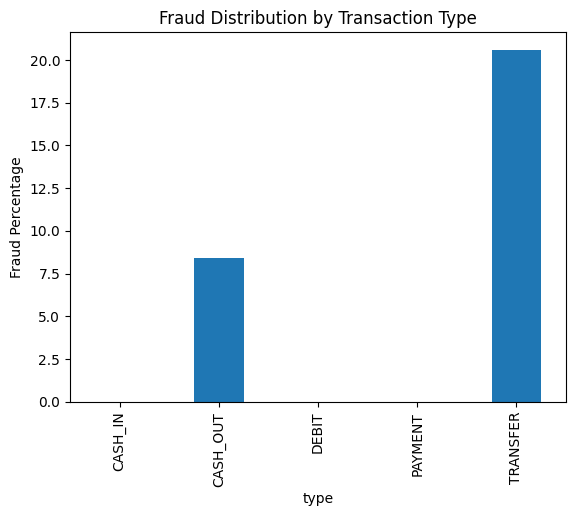

In [24]:
import matplotlib.pyplot as plt

fraud_stats['fraud_percentage'].plot(kind='bar')

plt.ylabel("Fraud Percentage")
plt.title("Fraud Distribution by Transaction Type")

plt.show()

We can see, the fraud transactions are coming from **Cash Out and Transfer** type transactions, so we have used these transaction types for training

Creating a set with the sequence number for all the **customer** nodes  
First cust_nodes creating with all account names with Initial **C**, that means a customer account

In [25]:
cust_nodes = all_nodes[all_nodes.str.startswith('C')].unique()

# Create mapping: string → integer
node_to_custid = {node: i for i, node in enumerate(cust_nodes)}

print("Total Nodes :",len(node_to_custid))
print("Some samples :", list(node_to_custid.items())[:10])

print("Customer nodes:",cust_nodes)

Total Nodes : 136480
Some samples : [('C475009342', 0), ('C272569438', 1), ('C1575403085', 2), ('C871918467', 3), ('C1139579110', 4), ('C25558209', 5), ('C1884000068', 6), ('C1318677343', 7), ('C1045455985', 8), ('C685169008', 9)]
Customer nodes: ['C475009342' 'C272569438' 'C1575403085' ... 'C1843501227' 'C657137249'
 'C646623849']


Creating a set with the sequence number for all the **merchant** nodes  
First cust_nodes creating with all account names with Initial **M**, that means a customer account

In [26]:
merch_nodes = all_nodes[all_nodes.str.startswith('M')].unique()

# Create mapping: string → integer
node_to_merchid = {node: i for i, node in enumerate(merch_nodes)}

print("Total Nodes :",len(node_to_merchid))
print("Some samples :", list(node_to_merchid.items())[:10])

print("Merchant nodes:",merch_nodes)

Total Nodes : 10346
Some samples : [('M1121086250', 0), ('M1013925111', 1), ('M561126912', 2), ('M408904476', 3), ('M2141256838', 4), ('M641413241', 5), ('M1135627393', 6), ('M588013212', 7), ('M1417971940', 8), ('M1110476145', 9)]
Merchant nodes: ['M1121086250' 'M1013925111' 'M561126912' ... 'M1250696349' 'M12952014'
 'M851090959']


Creating 2 datasets one for trasactions between customer to customer and another for customer to merchant  
Initially identifying the source account type and destination accunt type and based on that these 2 datasets are being created

In [27]:
PS['src_type'] = PS['nameOrig'].str[0]
PS['dst_type'] = PS['nameDest'].str[0]

cc_df = PS[
    (PS['src_type'] == 'C') &
    (PS['dst_type'] == 'C') &
    (PS['type'].isin(['TRANSFER', 'CASH_OUT', 'CASH_IN']))
]

cm_df = PS[
    (PS['src_type'] == 'C') &
    (PS['dst_type'] == 'M')
]

print("Customer → Customer :", len(cc_df))
print("Customer → Merchant :", len(cm_df))



Customer → Customer : 96958
Customer → Merchant : 10346


In [28]:
print(cc_df[['nameOrig', 'nameDest']].head())
print(cm_df[['nameOrig', 'nameDest']].head())

      nameOrig     nameDest
0   C475009342  C1814117380
1   C272569438  C1809716881
2  C1575403085  C1570256460
3   C871918467  C1796311996
4  C1139579110  C1167432890
       nameOrig     nameDest
12  C1851509763  M1121086250
31   C739651567  M1013925111
41  C1623408410   M561126912
44    C18119342   M408904476
52  C1078447055  M2141256838


In [29]:
dest_counts = PS_raw['nameDest'].value_counts()

print(dest_counts.head(20))

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
C977993101      96
C97730845       96
C392292416      95
C1899073220     92
C306206744      91
C1234776885     90
C1782113663     90
C998351292      89
C716083600      89
C909295153      88
Name: count, dtype: int64


In [30]:
cc_df['nameDest'].value_counts().describe()

count    28116.000000
mean         3.448499
std         11.301269
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        111.000000
Name: count, dtype: float64

In [31]:
top_dest = 'C1286084959'

PS_raw[PS_raw['nameDest'] == top_dest][['type','isFraud']].value_counts()

type      isFraud
CASH_OUT  0          45
CASH_IN   0          36
TRANSFER  0          30
DEBIT     0           2
Name: count, dtype: int64

In [32]:
cc_df[cc_df['nameDest'] == top_dest].shape

(111, 14)

In [33]:
cc_df[cc_df['nameDest'] == top_dest][['isFraud']].value_counts()

isFraud
0          111
Name: count, dtype: int64

In [34]:
top_dest = dest_counts.index[0]

PS_raw[
    PS_raw['nameDest'] == top_dest
]['type'].value_counts()

type
CASH_OUT    45
CASH_IN     36
TRANSFER    30
DEBIT        2
Name: count, dtype: int64

In [35]:
top_dests = (
    PS_raw['nameDest']
    .value_counts()
    .head(20)
    .index
)

for d in top_dests[:10]:
    print(
        d,
        (PS_raw['nameDest'] == d).sum()
    )

C1286084959 113
C985934102 109
C665576141 105
C2083562754 102
C248609774 101
C1590550415 101
C451111351 99
C1789550256 99
C1360767589 98
C1023714065 97


Creating Edge index tensor of customer nodes to customer nodes

In [36]:
import torch

# Map sender and receiver to IDs
src_cust = cc_df['nameOrig'].map(node_to_custid).values
dst_cust = cc_df['nameDest'].map(node_to_custid).values

# Create edge_index
cc_edge_index = torch.tensor([src_cust, dst_cust], dtype=torch.long)

print(cc_edge_index[:, :10])

tensor([[     0,      1,      2,      3,      4,      5,      6,      7,      8,
              9],
        [108213, 108214, 108215, 108216, 108217, 108218, 108219, 108220, 108221,
         108222]])


C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\4106858730.py:8: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ..\torch\csrc\utils\tensor_new.cpp:277.)
  cc_edge_index = torch.tensor([src_cust, dst_cust], dtype=torch.long)


Creating Edge index tensor of customer nodes to merchant nodes

In [37]:


# Map sender and receiver to IDs
src_cust = cm_df['nameOrig'].map(node_to_custid).values
dst_merch = cm_df['nameDest'].map(node_to_merchid).values

# Create edge_index
cm_edge_index = torch.tensor([src_cust, dst_merch], dtype=torch.long)

print(cm_edge_index[:, :10])

tensor([[ 12,  31,  41,  44,  52,  57,  95,  98, 107, 117],
        [  0,   1,   2,   3,   4,   5,   6,   7,   8,   9]])


In [38]:
#import sys
#!{sys.executable} -m pip install torch-geometric

**Creating Hetero graph data with Customer nodes, Merchant nodes, Customer to Customer edge, Customer to merchant edge**

In [39]:
import torch
from torch_geometric.data import HeteroData

# Create heterogeneous graph object
data = HeteroData()

# =========================================================
# NODE INFORMATION
# =========================================================

# Number of customer nodes
data['customer'].num_nodes = len(node_to_custid)

# Number of merchant nodes
data['merchant'].num_nodes = len(node_to_merchid)

# =========================================================
# CUSTOMER -> CUSTOMER RELATION
# (customer) --transfers--> (customer)
# =========================================================

data['customer', 'transfers', 'customer'].edge_index = cc_edge_index

# =========================================================
# CUSTOMER -> MERCHANT RELATION
# (customer) --pays--> (merchant)
# =========================================================

data['customer', 'pays', 'merchant'].edge_index = cm_edge_index

# =========================================================
# PRINT GRAPH SUMMARY
# =========================================================

print(data)

c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HeteroData(
  customer={ num_nodes=136480 },
  merchant={ num_nodes=10346 },
  (customer, transfers, customer)={ edge_index=[2, 96958] },
  (customer, pays, merchant)={ edge_index=[2, 10346] }
)


In [40]:
print(PS['type'].unique())

['TRANSFER' 'CASH_OUT' 'CASH_IN' 'PAYMENT' 'DEBIT']


In [41]:

print(PS[PS['type'].str.startswith('C')]['type'].unique())

['CASH_OUT' 'CASH_IN']


Mapping the **Transaction type** with **Transaction type ID**

In [42]:
type_mapping = {
    'TRANSFER': 0,
    'CASH_OUT': 1,
    'CASH_IN': 2,
    'PAYMENT': 3,
    'DEBIT': 4
}

PS['type_id'] = PS['type'].map(type_mapping)

print(PS['type_id'].unique())

[0 1 2 3 4]


This is another data analysis identifying which type of transaction is happening between cutomer to customer

In [43]:
type_mapping = {
    'TRANSFER': 0,
    'CASH_OUT': 1,
    'CASH_IN': 2,
    'PAYMENT': 3,
    'DEBIT': 4
}

cc_df['type_id'] = cc_df['type'].map(type_mapping)

print(cc_df['type_id'].unique())

[0 1 2]


C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\1117107478.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cc_df['type_id'] = cc_df['type'].map(type_mapping)


Creating **edge attributes for Customer to customer** edges

In [44]:
import torch

# Select edge feature columns
cc_edge_features = cc_df[[
 'amount',
 'type_id',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest'
]].values

# Convert to tensor
cc_edge_attr = torch.tensor(
    cc_edge_features,
    dtype=torch.float
)

# Check shape
print(cc_edge_attr.shape)

# View first few rows
print(cc_edge_attr[:5])

torch.Size([96958, 6])
tensor([[2.1648e+04, 0.0000e+00, 3.0610e+03, 0.0000e+00, 3.6729e+05, 3.8894e+05],
        [5.2732e+05, 1.0000e+00, 9.7739e+05, 4.5007e+05, 3.0874e+06, 3.7127e+06],
        [9.5239e+04, 2.0000e+00, 3.9948e+04, 1.3519e+05, 8.4589e+07, 8.4494e+07],
        [9.8681e+04, 1.0000e+00, 9.4768e+04, 0.0000e+00, 9.6054e+04, 1.9473e+05],
        [1.9254e+05, 1.0000e+00, 2.9905e+04, 0.0000e+00, 5.7195e+06, 5.9120e+06]])


In [45]:
cc_edge_label = cc_df['isFraud'].values

Assigning edge_label and edge_attribute in the Hetero data graph

In [46]:
data['customer', 'transfers', 'customer'].edge_label = cc_edge_label

In [47]:
data['customer', 'transfers', 'customer'].edge_attr = cc_edge_attr

Data analysis to find out what kind of transaction occuring between customer and merchant

In [48]:
type_mapping = {
    'TRANSFER': 0,
    'CASH_OUT': 1,
    'CASH_IN': 2,
    'PAYMENT': 3,
    'DEBIT': 4
}

cm_df['type_id'] = cm_df['type'].map(type_mapping)

print(cm_df['type_id'].unique())

[3]


C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\377302135.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cm_df['type_id'] = cm_df['type'].map(type_mapping)


Creating **edge attributes for Customer to merchant** edges

In [49]:
import torch

# Select edge feature columns
cm_edge_features = cm_df[[
 'amount',
 'type_id',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest'
]].values

# Convert to tensor
cm_edge_attr = torch.tensor(
    cm_edge_features,
    dtype=torch.float
)

# Check shape
print(cm_edge_attr.shape)

# View first few rows
print(cm_edge_attr[:5])

torch.Size([10346, 6])
tensor([[1.7836e+04, 3.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [8.9351e+03, 3.0000e+00, 4.0999e+04, 3.2064e+04, 0.0000e+00, 0.0000e+00],
        [1.8397e+04, 3.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [5.2034e+04, 3.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [2.6502e+02, 3.0000e+00, 1.4800e+02, 0.0000e+00, 0.0000e+00, 0.0000e+00]])


In [50]:
cm_edge_label = cm_df['isFraud'].values

Assigning edge_label and edge_attribute in the Hetero data graph

In [51]:
data['customer', 'pays', 'merchant'].edge_label = cm_edge_label

In [52]:
data['customer', 'pays', 'merchant'].edge_attr = cm_edge_attr

Updated Hetero graph

In [53]:
print(data)

HeteroData(
  customer={ num_nodes=136480 },
  merchant={ num_nodes=10346 },
  (customer, transfers, customer)={
    edge_index=[2, 96958],
    edge_label=[96958],
    edge_attr=[96958, 6],
  },
  (customer, pays, merchant)={
    edge_index=[2, 10346],
    edge_label=[10346],
    edge_attr=[10346, 6],
  }
)


Creating **customer nodes features**  
Creating features based on the Source customer and destination customer

In [54]:
from sklearn.preprocessing import StandardScaler

# Outgoing statistics
outgoing_stats = (
    PS.groupby('nameOrig')
      .agg(
          sent_amount=('amount', 'sum'),
          avg_txn_amount=('amount', 'mean'),
          outgoing_txn_count=('amount', 'count'),
          first_sent_step=('step', 'min'),
          last_sent_step=('step', 'max')
      )
)

# Incoming statistics
incoming_stats = (
    PS.groupby('nameDest')
      .agg(
          received_amount=('amount', 'sum'),
          incoming_txn_count=('amount', 'count'),
          first_received_step=('step', 'min'),
          last_received_step=('step', 'max')
      )
)

# Master customer list
customer_df = pd.DataFrame(index=cust_nodes)

# Join all features
customer_df = customer_df.join(outgoing_stats)
customer_df = customer_df.join(incoming_stats)

# Replace missing values
customer_df = customer_df.fillna(0)

# Active duration
customer_df['first_seen'] = customer_df[
    ['first_sent_step', 'first_received_step']
].replace(0, np.nan).min(axis=1)

customer_df['last_seen'] = customer_df[
    ['last_sent_step', 'last_received_step']
].max(axis=1)

customer_df['active_duration'] = (
    customer_df['last_seen'] - customer_df['first_seen']
)

# Avoid division by zero
customer_df['active_duration'] = (
    customer_df['active_duration']
    .fillna(0)
    .clip(lower=1)
)

# -------------------------------
# Velocity Features
# -------------------------------

# Outgoing velocity
customer_df['sent_velocity'] = (
    customer_df['sent_amount']
    / customer_df['active_duration']
)

# Incoming velocity
customer_df['received_velocity'] = (
    customer_df['received_amount']
    / customer_df['active_duration']
)

# Transaction frequency
customer_df['txn_frequency'] = (
    (customer_df['outgoing_txn_count']
     + customer_df['incoming_txn_count'])
    / customer_df['active_duration']
)

# Drop helper columns if not needed
customer_df = customer_df.drop(
    columns=[
        'first_sent_step',
        'last_sent_step',
        'first_received_step',
        'last_received_step',
        'first_seen',
        'last_seen'
    ]
)

# Final cleanup
customer_df = customer_df.fillna(0)



scaler = StandardScaler()

customer_x = torch.tensor(
    scaler.fit_transform(customer_df.values),
    dtype=torch.float
)

# Convert to tensor
#customer_x = torch.tensor(
    #customer_df.loc[cust_nodes].values,
    #dtype=torch.float
#)

print(customer_df.head())
print(customer_x.shape)

             sent_amount  avg_txn_amount  outgoing_txn_count  received_amount  \
C475009342      21648.18        21648.18                 1.0              0.0   
C272569438     527322.98       527322.98                 1.0              0.0   
C1575403085     95238.78        95238.78                 1.0              0.0   
C871918467      98680.62        98680.62                 1.0              0.0   
C1139579110    192542.66       192542.66                 1.0              0.0   

             incoming_txn_count  active_duration  sent_velocity  \
C475009342                  0.0              1.0       21648.18   
C272569438                  0.0              1.0      527322.98   
C1575403085                 0.0              1.0       95238.78   
C871918467                  0.0              1.0       98680.62   
C1139579110                 0.0              1.0      192542.66   

             received_velocity  txn_frequency  
C475009342                 0.0            1.0  
C272569438    

In [55]:
print(customer_df[
    [
        'active_duration',
        'sent_velocity',
        'received_velocity',
        'txn_frequency'
    ]
].describe())

       active_duration  sent_velocity  received_velocity  txn_frequency
count    136480.000000   1.364800e+05       1.364800e+05  136480.000000
mean          6.496776   3.431857e+05       1.189428e+05       0.985266
std          49.278226   1.257177e+06       7.077231e+05       0.116815
min           1.000000   0.000000e+00       0.000000e+00       0.003003
25%           1.000000   6.278632e+03       0.000000e+00       1.000000
50%           1.000000   1.142533e+05       0.000000e+00       1.000000
75%           1.000000   2.797496e+05       0.000000e+00       1.000000
max         708.000000   6.278542e+07       2.972956e+07       2.000000


Confirming any NULL features present or not

In [56]:
zero_cols = customer_df.columns[(customer_df == 0).all()]

print(list(zero_cols))

[]


In [57]:
zero_cols = (customer_df == 0).all()

print(zero_cols)

sent_amount           False
avg_txn_amount        False
outgoing_txn_count    False
received_amount       False
incoming_txn_count    False
active_duration       False
sent_velocity         False
received_velocity     False
txn_frequency         False
dtype: bool


Creating **merchant nodes** features

In [58]:


# Incoming statistics
incoming_stats = (
    PS.groupby('nameDest')
      .agg(
          received_payment=('amount', 'sum'),
          customer_count=('nameOrig', 'nunique'),
          avg_pmt_amount=('amount', 'mean'),
          first_received_step=('step', 'min'),
          last_received_step=('step', 'max')
      )
)


# Merge all features
merchant_df = pd.DataFrame(index=merch_nodes)


merchant_df = merchant_df.join(incoming_stats)

# Replace missing values
merchant_df = merchant_df.fillna(0)

# Active duration
merchant_df['first_seen'] = merchant_df['first_received_step']

merchant_df['last_seen'] = merchant_df['last_received_step']

merchant_df['active_duration'] = (
    merchant_df['last_seen'] - merchant_df['first_seen']
)

# Avoid division by zero
merchant_df['active_duration'] = (
    merchant_df['active_duration']
    .fillna(0)
    .clip(lower=1)
)

# -------------------------------
# Velocity Features
# -------------------------------



# Incoming velocity
merchant_df['received_velocity'] = (
    merchant_df['received_payment']
    / merchant_df['active_duration']
)

# Transaction frequency
merchant_df['customer_frequency'] = (
    (merchant_df['customer_count'])
    / merchant_df['active_duration']
)

# Drop helper columns if not needed
merchant_df = merchant_df.drop(
    columns=[
        'first_received_step',
        'last_received_step',
        'first_seen',
        'last_seen'
    ]
)

# Final cleanup
merchant_df = merchant_df.fillna(0)

scaler = StandardScaler()

merchant_x = torch.tensor(
    scaler.fit_transform(merchant_df.values),
    dtype=torch.float
)


# Convert to tensor
#merchant_x = torch.tensor(
    #merchant_df.values,
    #dtype=torch.float
#)

print(merchant_x.shape)
print(merchant_df.head())

torch.Size([10346, 6])
             received_payment  customer_count  avg_pmt_amount  \
M1121086250          17835.70               1        17835.70   
M1013925111           8935.13               1         8935.13   
M561126912           18397.45               1        18397.45   
M408904476           52033.98               1        52033.98   
M2141256838            265.02               1          265.02   

             active_duration  received_velocity  customer_frequency  
M1121086250                1           17835.70                 1.0  
M1013925111                1            8935.13                 1.0  
M561126912                 1           18397.45                 1.0  
M408904476                 1           52033.98                 1.0  
M2141256838                1             265.02                 1.0  


Adding the features in hetero graph

In [59]:
data['customer'].x = customer_x
data['merchant'].x = merchant_x

In [60]:
print(data)

HeteroData(
  customer={
    num_nodes=136480,
    x=[136480, 9],
  },
  merchant={
    num_nodes=10346,
    x=[10346, 6],
  },
  (customer, transfers, customer)={
    edge_index=[2, 96958],
    edge_label=[96958],
    edge_attr=[96958, 6],
  },
  (customer, pays, merchant)={
    edge_index=[2, 10346],
    edge_label=[10346],
    edge_attr=[10346, 6],
  }
)


Scaling the customer to customer edge features

In [61]:
from sklearn.preprocessing import StandardScaler
import torch

edge_type = ('customer', 'transfers', 'customer')

scaler = StandardScaler()

scaled_edge_attr = scaler.fit_transform(
    data[edge_type].edge_attr.numpy()
)

data[edge_type].edge_attr = torch.tensor(
    scaled_edge_attr,
    dtype=torch.float
)

As we have seen earlier, only **cash out and transafer** transactions are fraud which occurs between customer to customer, we have taken **customer to customer** edge for training

In [62]:
edge_type = ('customer', 'transfers', 'customer')

edge_index = data[edge_type].edge_index
edge_attr = data[edge_type].edge_attr
edge_label = data[edge_type].edge_label

Splitting train, test and validation samples

In [63]:
import torch
from sklearn.model_selection import train_test_split

num_edges = len(edge_label)

indices = torch.arange(num_edges)

In [64]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.3,
    stratify=edge_label,
    random_state=42
)

In [65]:
train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.3,
    stratify=edge_label[train_idx],
    random_state=42
)

#print(train_idx)

In [66]:
data[edge_type].train_idx = torch.tensor(train_idx)
data[edge_type].val_idx = torch.tensor(val_idx)
data[edge_type].test_idx = torch.tensor(test_idx)

C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\928502301.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data[edge_type].train_idx = torch.tensor(train_idx)
C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\928502301.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data[edge_type].val_idx = torch.tensor(val_idx)
C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\928502301.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data[edge_type].test_idx = torch.tensor(test_idx)


In [67]:
train_edge_index = edge_index[:, train_idx]
train_edge_attr = edge_attr[train_idx]
train_edge_label = edge_label[train_idx]

In [68]:
val_edge_index = edge_index[:, val_idx]
val_edge_attr = edge_attr[val_idx]
val_edge_label = edge_label[val_idx]

In [69]:
test_edge_index = edge_index[:, test_idx]
test_edge_attr = edge_attr[test_idx]
test_edge_label = edge_label[test_idx]

**Graph Sage GNN**  
Since Customer features and merchant features are different in numbers, we have taken (-1,-1) as input

In [70]:

import torch
from torch_geometric.nn import SAGEConv
from torch_geometric.nn import to_hetero
import torch.nn.functional as F

class GraphSAGE(torch.nn.Module):
    def __init__(self,  hidden_channels):
        super().__init__()
        torch.manual_seed(1234567)

        self.sage1 = SAGEConv((-1, -1), hidden_channels)
        self.sage2 = SAGEConv((-1, -1), hidden_channels)

    def forward(self, x, edge_index):
        h = self.sage1(x, edge_index)
        h = F.relu(h)
        h = F.dropout(h, p=0.4, training=self.training)

        h = self.sage2(h, edge_index)
        h = F.relu(h)

        return h   # node embeddings

model = GraphSAGE(hidden_channels=8)
model = to_hetero(model, data.metadata())
print(model)

GraphModule(
  (sage1): ModuleDict(
    (customer__transfers__customer): SAGEConv((-1, -1), 8, aggr=mean)
    (customer__pays__merchant): SAGEConv((-1, -1), 8, aggr=mean)
  )
  (sage2): ModuleDict(
    (customer__transfers__customer): SAGEConv((-1, -1), 8, aggr=mean)
    (customer__pays__merchant): SAGEConv((-1, -1), 8, aggr=mean)
  )
)



def forward(self, x, edge_index):
    x_dict = torch_geometric_nn_to_hetero_transformer_get_dict(x);  x = None
    x__customer = x_dict.get('customer', None)
    x__merchant = x_dict.get('merchant', None);  x_dict = None
    edge_index_dict = torch_geometric_nn_to_hetero_transformer_get_dict(edge_index);  edge_index = None
    edge_index__customer__transfers__customer = edge_index_dict.get(('customer', 'transfers', 'customer'), None)
    edge_index__customer__pays__merchant = edge_index_dict.get(('customer', 'pays', 'merchant'), None);  edge_index_dict = None
    sage1__customer = self.sage1.customer__transfers__customer(x__customer, edge_index__cust

c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\torch_geometric\nn\to_hetero_transformer.py:120: UserWarning: Found function 'dropout' with keyword argument 'training'. During FX tracing, this will likely be baked in as a constant value. Consider replacing this function by a module to properly encapsulate its training flag.
  return transformer.transform()


**Edge Classifier linear model**  
This model identifies if an edge between 2 nodes are fraud or normal

In [71]:
class EdgeClassifier(torch.nn.Module):
    def __init__(self, hidden_channels, edge_attr_dim):
        super().__init__()
        torch.manual_seed(1234567)
        self.lin1 = torch.nn.Linear(hidden_channels * 2 + edge_attr_dim, 18)
        self.lin2 = torch.nn.Linear(18, 1)

    def forward(self, z_src, z_dst, edge_attr_dim):
        z = torch.cat([z_src, z_dst, edge_attr_dim], dim=-1)
        h = self.lin1(z)
        h = F.relu(h)

        h = self.lin2(h)

        return h.view(-1)

classifier = EdgeClassifier(hidden_channels=8, edge_attr_dim=6)

Getting node embeddings from graph model
Then taking the embeddings of source and destination nodes from the edge_index.  
Then with advanced indexing of python the coerresponding source and destination nodes embedding.  
Then using edge classifier on those nodes, we are finding the edge logits

In [72]:
z = model(data.x_dict, data.edge_index_dict)

print("train edge_index :", train_edge_index[:,:10])

src, dst = train_edge_index

print("training sources :",src[:10])
print("training destinations :",dst[:10])

z_customer = z['customer']
#z_dest_customer = z['customer']

z_src = z_customer[src]
z_dst = z_customer[dst]

print("training source embeddings :",z_src[:10])
print("training destination embeddings :",z_dst[:10])
print(z_src.shape)
print(z_dst.shape)

logits = classifier(z_src, z_dst, train_edge_attr)

print("few training logits :",logits.view(-1)[:10])

train edge_index : tensor([[ 25604,  33912,  54556,  63776,  10506,  71296,  29567, 105812,  40632,
         103848],
        [108976, 108569, 123247, 125512, 110921, 127409, 108338, 108667, 108221,
         126951]])
training sources : tensor([ 25604,  33912,  54556,  63776,  10506,  71296,  29567, 105812,  40632,
        103848])
training destinations : tensor([108976, 108569, 123247, 125512, 110921, 127409, 108338, 108667, 108221,
        126951])
training source embeddings : tensor([[5.5306e-02, 2.7561e-02, 5.6424e-02, 2.9806e-01, 0.0000e+00, 1.1786e-01,
         2.1979e-01, 1.7478e-01],
        [3.7451e-02, 0.0000e+00, 1.1691e-01, 2.8819e-01, 0.0000e+00, 1.1487e-01,
         2.5840e-01, 3.4064e-05],
        [7.7002e-02, 6.3853e-02, 7.6800e-02, 2.0967e-01, 0.0000e+00, 4.5082e-02,
         1.5757e-01, 1.1096e-01],
        [0.0000e+00, 8.7566e-03, 4.8485e-02, 4.6183e-01, 0.0000e+00, 2.3098e-01,
         2.5615e-01, 1.4831e-01],
        [0.0000e+00, 2.0099e-01, 0.0000e+00, 1.3380e-01,

Training loop for graph model
Then taking the embeddings of source and destination nodes
Then using edge classifier on those nodes

In [73]:
import torch
import torch.nn.functional as F
from torch.optim import Adam

# =========================================================
# DEVICE
# =========================================================

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# =========================================================
# MODEL INITIALIZATION
# =========================================================


hidden_channels = 8
edge_attr_dim = data[edge_type].edge_attr.shape[1]
data = data.to(device)
model = GraphSAGE(hidden_channels)
model = to_hetero(model, data.metadata())
model = model.to(device)

classifier = EdgeClassifier(
    hidden_channels,
    edge_attr_dim
).to(device)

# =========================================================
# MOVE DATA TO DEVICE
# =========================================================


full_edge_index = data.edge_index_dict

train_edge_index = train_edge_index.to(device)

train_edge_attr = torch.tensor(
    train_edge_attr,
    dtype=torch.float
).to(device)

train_edge_label = torch.tensor(
    train_edge_label,
    dtype=torch.float
).to(device)

# =========================================================
# OPTIMIZER
# =========================================================

optimizer = Adam(
    list(model.parameters()) +
    list(classifier.parameters()),
    lr=0.001
)

# =========================================================
# CLASS IMBALANCE HANDLING
# =========================================================

num_negative = (train_edge_label == 0).sum()
num_positive = (train_edge_label == 1).sum()

pos_weight = torch.tensor(
    [num_negative / num_positive],
    dtype=torch.float
).to(device)

# =========================================================
# TRAINING FUNCTION
# =========================================================

def train():

    model.train()
    classifier.train()

    optimizer.zero_grad()

    # -----------------------------------------------------
    # Step 1: Generate node embeddings from FULL graph
    # -----------------------------------------------------

    z = model(data.x_dict, full_edge_index)

    # -----------------------------------------------------
    # Step 2: Select ONLY training edges
    # -----------------------------------------------------

    src, dst = train_edge_index

    z_customer = z['customer']
    #z_merchant = z['merchant']

    z_src = z_customer[src]
    z_dst = z_customer[dst]

    # -----------------------------------------------------
    # Step 3: Edge fraud prediction
    # -----------------------------------------------------

    logits = classifier(
        z_src,
        z_dst,
        train_edge_attr
    )

    # -----------------------------------------------------
    # Step 4: Loss computation
    # -----------------------------------------------------

    loss = F.binary_cross_entropy_with_logits(
        logits.view(-1),
        train_edge_label,
        pos_weight=pos_weight
    )

    # -----------------------------------------------------
    # Step 5: Backpropagation
    # -----------------------------------------------------

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
    )

    optimizer.step()

    return loss.item()



c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\torch_geometric\nn\to_hetero_transformer.py:120: UserWarning: Found function 'dropout' with keyword argument 'training'. During FX tracing, this will likely be baked in as a constant value. Consider replacing this function by a module to properly encapsulate its training flag.
  return transformer.transform()
C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\2464721938.py:38: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_edge_attr = torch.tensor(


In [74]:
val_edge_index = val_edge_index.to(device)

val_edge_attr = torch.tensor(
    val_edge_attr,
    dtype=torch.float
).to(device)

val_edge_label = torch.tensor(
    val_edge_label,
    dtype=torch.float
).to(device)


test_edge_index = test_edge_index.to(device)

test_edge_attr = torch.tensor(
    test_edge_attr,
    dtype=torch.float
).to(device)

test_edge_label = torch.tensor(
    test_edge_label,
    dtype=torch.float
).to(device)

C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\3852479201.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_edge_attr = torch.tensor(
C:\Users\KAUSTAV\AppData\Local\Temp\ipykernel_18032\3852479201.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_edge_attr = torch.tensor(


Since the number of fraud transactions are very small compared to correct transactions, we have calculated **pos_weight** to give enough weightage on the small non fraud transactions

In [75]:
print(pos_weight)

tensor([10.8064])


In [76]:
print("Train frauds:", train_edge_label.sum())
print("Val frauds:", val_edge_label.sum())
print("Test frauds:", test_edge_label.sum())

Train frauds: tensor(4024.)
Val frauds: tensor(1725.)
Test frauds: tensor(2464.)


In [77]:
# =========================================================
# IMPORT EVALUATION METRICS
# =========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# =========================================================
# EVALUATION FUNCTION
# =========================================================

@torch.no_grad()

def evaluate(edge_index_split,
             edge_attr_split,
             edge_label_split):

    model.eval()
    classifier.eval()

    # -----------------------------------------------------
    # Step 1: Generate node embeddings from FULL graph
    # -----------------------------------------------------

    z = model(data.x_dict, full_edge_index)

    # -----------------------------------------------------
    # Step 2: Select evaluation edges
    # -----------------------------------------------------

    src, dst = edge_index_split

    z_customer = z['customer']
    #z_merchant = z['merchant']

    z_src = z_customer[src]
    z_dst = z_customer[dst]

    # -----------------------------------------------------
    # Step 3: Predict logits
    # -----------------------------------------------------

    logits = classifier(
        z_src,
        z_dst,
        edge_attr_split
    )


    # -----------------------------------------------------
    # Step 4: Convert logits -> probabilities
    # -----------------------------------------------------

    probs = torch.sigmoid(
        logits.view(-1)
    )

    # -----------------------------------------------------
    # Step 5: Convert probabilities -> predictions
    # -----------------------------------------------------

    preds = (probs > 0.5).long()

    # -----------------------------------------------------
    # Convert to CPU numpy
    # -----------------------------------------------------

    labels_np = edge_label_split.detach().cpu().numpy()

    probs_np = probs.detach().cpu().numpy()

    preds_np = preds.detach().cpu().numpy()



    # -----------------------------------------------------
    # Compute metrics
    # -----------------------------------------------------

    accuracy = accuracy_score(
        labels_np,
        preds_np
    )

    precision = precision_score(
        labels_np,
        preds_np,
        zero_division=0
    )

    recall = recall_score(
        labels_np,
        preds_np,
        zero_division=0
    )

    f1 = f1_score(
        labels_np,
        preds_np,
        zero_division=0
    )

    auc = roc_auc_score(
        labels_np,
        probs_np
    )

    cm = confusion_matrix(
        labels_np,
        preds_np
    )

    # -----------------------------------------------------
    # Return metrics
    # -----------------------------------------------------

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'ROC-AUC': auc,
        'Confusion Matrix': cm
    }

In [78]:
print(torch.isnan(train_edge_attr).sum())
print(torch.isinf(train_edge_attr).sum())

print(train_edge_attr.max())
print(train_edge_attr.min())

tensor(0)
tensor(0)
tensor(42.4069)
tensor(-1.5527)


In [79]:
print(torch.isnan(logits).sum())
print(torch.isnan(z_customer).sum())
#print(torch.isnan(z_merchant).sum())

tensor(0)
tensor(0)


Analyzing the data to identify the nodes pattern that is **repetitive in transactions**

In [80]:
src_nodes = edge_index[0].cpu().numpy()
dst_nodes = edge_index[1].cpu().numpy()

all_nodes = np.concatenate(
    [src_nodes, dst_nodes]
)

unique_nodes = np.unique(all_nodes)

print("Unique nodes:", len(unique_nodes))
print("Total edge endpoints:", len(all_nodes))

Unique nodes: 125074
Total edge endpoints: 193916


In [81]:
for txn_type in PS['type'].unique():

    dest_counts = (
        PS[PS['type'] == txn_type]['nameDest']
        .value_counts()
    )

    print(f"\n===== {txn_type} =====")

    print("Destinations >1 :", (dest_counts > 1).sum())
    print("Destinations >5 :", (dest_counts > 5).sum())
    print("Destinations >10:", (dest_counts > 10).sum())
    print("Max occurrences :", dest_counts.max())


===== TRANSFER =====
Destinations >1 : 1311
Destinations >5 : 1140
Destinations >10: 571
Max occurrences : 31

===== CASH_OUT =====
Destinations >1 : 1670
Destinations >5 : 1247
Destinations >10: 1210
Max occurrences : 46

===== CASH_IN =====
Destinations >1 : 1409
Destinations >5 : 1213
Destinations >10: 1167
Max occurrences : 46

===== PAYMENT =====
Destinations >1 : 0
Destinations >5 : 0
Destinations >10: 0
Max occurrences : 1

===== DEBIT =====
Destinations >1 : 145
Destinations >5 : 0
Destinations >10: 0
Max occurrences : 5


In [82]:
cc_df['nameOrig'].value_counts().describe()

count    96958.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: count, dtype: float64

In [83]:
cc_df['nameDest'].value_counts().describe()

count    28116.000000
mean         3.448499
std         11.301269
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        111.000000
Name: count, dtype: float64

In [84]:
PS_raw['nameOrig'].value_counts().describe()

count    6.353307e+06
mean     1.001466e+00
std      3.832002e-02
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.000000e+00
Name: count, dtype: float64

In [85]:
PS_raw['nameDest'].value_counts().describe()

count    2.722362e+06
mean     2.337169e+00
std      4.549264e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.130000e+02
Name: count, dtype: float64

In [86]:
print(PS_raw['nameDest'].nunique())

print(cc_df['nameDest'].nunique())

2722362
28116


In [87]:
print(len(PS_raw))

print(len(cc_df))

6362620
96958


**Training Loop**

In [88]:
# =========================================================
# TRAINING LOOP WITH VALIDATION
# =========================================================

epochs = 201

for epoch in range(epochs):

    loss = train()

    # -----------------------------------------------------
    # Validation every 10 epochs
    # -----------------------------------------------------

    if epoch % 10 == 0:

        val_metrics = evaluate(
            val_edge_index,
            val_edge_attr,
            val_edge_label
        )

        print(f"\nEpoch {epoch:03d}")

        print(f"Train Loss : {loss:.4f}")

        print(f"Validation Accuracy : {val_metrics['Accuracy']:.4f}")

        print(f"Validation Precision: {val_metrics['Precision']:.4f}")

        print(f"Validation Recall   : {val_metrics['Recall']:.4f}")

        print(f"Validation F1 Score : {val_metrics['F1']:.4f}")

        print(f"Validation ROC-AUC  : {val_metrics['ROC-AUC']:.4f}")


Epoch 000
Train Loss : 1.2905
Validation Accuracy : 0.8318
Validation Precision: 0.0517
Validation Recall   : 0.0568
Validation F1 Score : 0.0541
Validation ROC-AUC  : 0.3713

Epoch 010
Train Loss : 1.2447
Validation Accuracy : 0.8944
Validation Precision: 0.2856
Validation Recall   : 0.1641
Validation F1 Score : 0.2084
Validation ROC-AUC  : 0.7807

Epoch 020
Train Loss : 1.1973
Validation Accuracy : 0.9197
Validation Precision: 0.5456
Validation Recall   : 0.3119
Validation F1 Score : 0.3969
Validation ROC-AUC  : 0.9164

Epoch 030
Train Loss : 1.1411
Validation Accuracy : 0.9319
Validation Precision: 0.6063
Validation Recall   : 0.5606
Validation F1 Score : 0.5825
Validation ROC-AUC  : 0.9402

Epoch 040
Train Loss : 1.0646
Validation Accuracy : 0.9198
Validation Precision: 0.5193
Validation Recall   : 0.7165
Validation F1 Score : 0.6022
Validation ROC-AUC  : 0.9473

Epoch 050
Train Loss : 0.9703
Validation Accuracy : 0.9082
Validation Precision: 0.4755
Validation Recall   : 0.8116
Va

In [89]:
# =========================================================
# FINAL TEST EVALUATION
# =========================================================

test_metrics = evaluate(
    test_edge_index,
    test_edge_attr,
    test_edge_label
)

print("\n================ TEST RESULTS ================")

print(f"Test Accuracy : {test_metrics['Accuracy']:.4f}")

print(f"Test Precision: {test_metrics['Precision']:.4f}")

print(f"Test Recall   : {test_metrics['Recall']:.4f}")

print(f"Test F1 Score : {test_metrics['F1']:.4f}")

print(f"Test ROC-AUC  : {test_metrics['ROC-AUC']:.4f}")

print("\nConfusion Matrix:")

print(test_metrics['Confusion Matrix'])




================ TEST RESULTS ================
Test Accuracy : 0.8497
Test Precision: 0.3580
Test Recall   : 0.9761
Test F1 Score : 0.5239
Test ROC-AUC  : 0.9625

Confusion Matrix:
[[22311  4313]
 [   59  2405]]


**Implementing *GAT GNN model* to do the comparative study**

In [90]:
from torch_geometric.nn import GATConv
import torch.nn.functional as F
from torch_geometric.nn import to_hetero


class GAT(torch.nn.Module):
    def __init__(self, hidden_channels, heads):
        super().__init__()
        torch.manual_seed(1234567)
        self.conv1 = GATConv((-1,-1), hidden_channels,heads=2, concat=True, add_self_loops=False)  # TODO
        self.conv2 = GATConv((-1,-1), hidden_channels * 2,heads=2, concat=False, add_self_loops=False)  # TODO
        

    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.6, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.6, training=self.training)
        x = self.conv2(x, edge_index)
        x = F.elu(x)
        return x

gat_model = GAT(hidden_channels=4, heads=2)
gat_model = to_hetero(gat_model, data.metadata())
print(gat_model)

GraphModule(
  (conv1): ModuleDict(
    (customer__transfers__customer): GATConv((-1, -1), 4, heads=2)
    (customer__pays__merchant): GATConv((-1, -1), 4, heads=2)
  )
  (conv2): ModuleDict(
    (customer__transfers__customer): GATConv((-1, -1), 8, heads=2)
    (customer__pays__merchant): GATConv((-1, -1), 8, heads=2)
  )
)



def forward(self, x, edge_index):
    x_dict = torch_geometric_nn_to_hetero_transformer_get_dict(x);  x = None
    x__customer = x_dict.get('customer', None)
    x__merchant = x_dict.get('merchant', None);  x_dict = None
    edge_index_dict = torch_geometric_nn_to_hetero_transformer_get_dict(edge_index);  edge_index = None
    edge_index__customer__transfers__customer = edge_index_dict.get(('customer', 'transfers', 'customer'), None)
    edge_index__customer__pays__merchant = edge_index_dict.get(('customer', 'pays', 'merchant'), None);  edge_index_dict = None
    dropout__customer = torch.nn.functional.dropout(x__customer, p = 0.6, training = True, inplace = Fal

c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\torch_geometric\nn\to_hetero_transformer.py:120: UserWarning: Found function 'dropout' with keyword argument 'training'. During FX tracing, this will likely be baked in as a constant value. Consider replacing this function by a module to properly encapsulate its training flag.
  return transformer.transform()
c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\torch_geometric\nn\to_hetero_transformer.py:120: UserWarning: Found function 'dropout_1' with keyword argument 'training'. During FX tracing, this will likely be baked in as a constant value. Consider replacing this function by a module to properly encapsulate its training flag.
  return transformer.transform()


In [91]:
z_gat = gat_model(data.x_dict, data.edge_index_dict)

gat_classifier = EdgeClassifier(hidden_channels=8, edge_attr_dim=6)

print("train edge_index :", train_edge_index[:,:10])


print(train_edge_index.shape)

src, dst = train_edge_index

print("training sources :",src[:10])
print("training destinations :",dst[:10])

z_gat_customer = z_gat['customer']
#z_dest_customer = z['customer']

z_gat_src = z_gat_customer[src]
z_gat_dst = z_gat_customer[dst]

print("training source embeddings :",z_gat_src[:10])
print("training destination embeddings :",z_gat_dst[:10])

print(train_edge_attr.shape)
print(z_gat_src.shape)
print(z_gat_dst.shape)

logits_gat = gat_classifier(z_gat_src, z_gat_dst, train_edge_attr)

print("few training logits :",logits.view(-1)[:10])

train edge_index : tensor([[ 25604,  33912,  54556,  63776,  10506,  71296,  29567, 105812,  40632,
         103848],
        [108976, 108569, 123247, 125512, 110921, 127409, 108338, 108667, 108221,
         126951]])
torch.Size([2, 47509])
training sources : tensor([ 25604,  33912,  54556,  63776,  10506,  71296,  29567, 105812,  40632,
        103848])
training destinations : tensor([108976, 108569, 123247, 125512, 110921, 127409, 108338, 108667, 108221,
        126951])
training source embeddings : tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]], grad_fn=<SliceBackward0>)
training destination embeddings : tensor([[0.,

**GAT** Training loop

In [92]:
import torch
import torch.nn.functional as F
from torch.optim import Adam




# =========================================================
# MODEL INITIALIZATION
# =========================================================



edge_attr_dim = data[edge_type].edge_attr.shape[1]
data = data.to(device)
gat_model = GAT(hidden_channels=4, heads=2)
gat_model = to_hetero(gat_model, data.metadata())
gat_model = gat_model.to(device)

gat_classifier = EdgeClassifier(
    hidden_channels =8,
    edge_attr_dim = 6
).to(device)


# =========================================================
# OPTIMIZER
# =========================================================

gat_optimizer = Adam(
    list(gat_model.parameters()) +
    list(gat_classifier.parameters()),
    lr=0.001
)

# =========================================================
# TRAINING FUNCTION
# =========================================================

def gat_train():

    gat_model.train()
    gat_classifier.train()

    gat_optimizer.zero_grad()

    # -----------------------------------------------------
    # Step 1: Generate node embeddings from FULL graph
    # -----------------------------------------------------

    z_gat = gat_model(data.x_dict, full_edge_index)

    # -----------------------------------------------------
    # Step 2: Select ONLY training edges
    # -----------------------------------------------------

    src, dst = train_edge_index

    z_gat_customer = z_gat['customer']
    #z_merchant = z['merchant']

    z_gat_src = z_gat_customer[src]
    z_gat_dst = z_gat_customer[dst]

    # -----------------------------------------------------
    # Step 3: Edge fraud prediction
    # -----------------------------------------------------

    logits_gat = gat_classifier(
        z_gat_src,
        z_gat_dst,
        train_edge_attr
    )

    # -----------------------------------------------------
    # Step 4: Loss computation
    # -----------------------------------------------------

    loss = F.binary_cross_entropy_with_logits(
        logits_gat.view(-1),
        train_edge_label,
        pos_weight=pos_weight
    )

    # -----------------------------------------------------
    # Step 5: Backpropagation
    # -----------------------------------------------------

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
    gat_model.parameters(),
    max_norm=1.0
    )

    gat_optimizer.step()

    return loss.item()

c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\torch_geometric\nn\to_hetero_transformer.py:120: UserWarning: Found function 'dropout' with keyword argument 'training'. During FX tracing, this will likely be baked in as a constant value. Consider replacing this function by a module to properly encapsulate its training flag.
  return transformer.transform()
c:\Users\KAUSTAV\AppData\Local\Programs\Python\Python310\lib\site-packages\torch_geometric\nn\to_hetero_transformer.py:120: UserWarning: Found function 'dropout_1' with keyword argument 'training'. During FX tracing, this will likely be baked in as a constant value. Consider replacing this function by a module to properly encapsulate its training flag.
  return transformer.transform()


In [93]:
# =========================================================
# EVALUATION FUNCTION
# =========================================================

@torch.no_grad()

def gat_evaluate(edge_index_split,
             edge_attr_split,
             edge_label_split):

    gat_model.eval()
    gat_classifier.eval()

    # -----------------------------------------------------
    # Step 1: Generate node embeddings from FULL graph
    # -----------------------------------------------------

    z_gat = gat_model(data.x_dict, full_edge_index)

    # -----------------------------------------------------
    # Step 2: Select evaluation edges
    # -----------------------------------------------------

    src, dst = edge_index_split

    z_gat_customer = z_gat['customer']
    #z_merchant = z['merchant']

    z_gat_src = z_gat_customer[src]
    z_gat_dst = z_gat_customer[dst]

    # -----------------------------------------------------
    # Step 3: Predict logits
    # -----------------------------------------------------

    gat_logits = gat_classifier(
        z_gat_src,
        z_gat_dst,
        edge_attr_split
    )


    # -----------------------------------------------------
    # Step 4: Convert logits -> probabilities
    # -----------------------------------------------------

    gat_probs = torch.sigmoid(
        gat_logits.view(-1)
    )

    # -----------------------------------------------------
    # Step 5: Convert probabilities -> predictions
    # -----------------------------------------------------

    gat_preds = (gat_probs > 0.5).long()

    # -----------------------------------------------------
    # Convert to CPU numpy
    # -----------------------------------------------------

    gat_labels_np = edge_label_split.detach().cpu().numpy()

    gat_probs_np = gat_probs.detach().cpu().numpy()

    gat_preds_np = gat_preds.detach().cpu().numpy()



    # -----------------------------------------------------
    # Compute metrics
    # -----------------------------------------------------

    gat_accuracy = accuracy_score(
        gat_labels_np,
        gat_preds_np
    )

    gat_precision = precision_score(
        gat_labels_np,
        gat_preds_np,
        zero_division=0
    )

    gat_recall = recall_score(
        gat_labels_np,
        gat_preds_np,
        zero_division=0
    )

    gat_f1 = f1_score(
        gat_labels_np,
        gat_preds_np,
        zero_division=0
    )

    gat_auc = roc_auc_score(
        gat_labels_np,
        gat_probs_np
    )

    gat_cm = confusion_matrix(
        gat_labels_np,
        gat_preds_np
    )

    # -----------------------------------------------------
    # Return metrics
    # -----------------------------------------------------

    return {
        'GAT Accuracy': gat_accuracy,
        'GAT Precision': gat_precision,
        'GAT Recall': gat_recall,
        'GAT F1': gat_f1,
        'GAT ROC-AUC': gat_auc,
        'GAT Confusion Matrix': gat_cm
    }

In [94]:
# =========================================================
# TRAINING LOOP WITH VALIDATION
# =========================================================

epochs = 201

for epoch in range(epochs):

    gat_loss = gat_train()

    # -----------------------------------------------------
    # Validation every 10 epochs
    # -----------------------------------------------------

    if epoch % 10 == 0:

        gat_val_metrics = gat_evaluate(
            val_edge_index,
            val_edge_attr,
            val_edge_label
        )

        print(f"\nEpoch {epoch:03d}")

        print(f"GAT Train Loss : {gat_loss:.4f}")

        print(f"GAT Validation Accuracy : {gat_val_metrics['GAT Accuracy']:.4f}")

        print(f"GAT Validation Precision: {gat_val_metrics['GAT Precision']:.4f}")

        print(f"GAT Validation Recall   : {gat_val_metrics['GAT Recall']:.4f}")

        print(f"GAT Validation F1 Score : {gat_val_metrics['GAT F1']:.4f}")

        print(f"GAT Validation ROC-AUC  : {gat_val_metrics['GAT ROC-AUC']:.4f}")


Epoch 000
GAT Train Loss : 1.2828
GAT Validation Accuracy : 0.8210
GAT Validation Precision: 0.1209
GAT Validation Recall   : 0.1774
GAT Validation F1 Score : 0.1438
GAT Validation ROC-AUC  : 0.3548

Epoch 010
GAT Train Loss : 1.2543
GAT Validation Accuracy : 0.8676
GAT Validation Precision: 0.2341
GAT Validation Recall   : 0.2475
GAT Validation F1 Score : 0.2406
GAT Validation ROC-AUC  : 0.5485

Epoch 020
GAT Train Loss : 1.2288
GAT Validation Accuracy : 0.8530
GAT Validation Precision: 0.2588
GAT Validation Recall   : 0.3942
GAT Validation F1 Score : 0.3124
GAT Validation ROC-AUC  : 0.7983

Epoch 030
GAT Train Loss : 1.2033
GAT Validation Accuracy : 0.8344
GAT Validation Precision: 0.3006
GAT Validation Recall   : 0.7194
GAT Validation F1 Score : 0.4240
GAT Validation ROC-AUC  : 0.8432

Epoch 040
GAT Train Loss : 1.1756
GAT Validation Accuracy : 0.8216
GAT Validation Precision: 0.2897
GAT Validation Recall   : 0.7617
GAT Validation F1 Score : 0.4197
GAT Validation ROC-AUC  : 0.8700


In [95]:
# =========================================================
# FINAL TEST EVALUATION
# =========================================================

gat_test_metrics = gat_evaluate(
    test_edge_index,
    test_edge_attr,
    test_edge_label
)

print("\n================ TEST RESULTS ================")

print(f"GAT Test Accuracy : {gat_test_metrics['GAT Accuracy']:.4f}")

print(f"GAT Test Precision: {gat_test_metrics['GAT Precision']:.4f}")

print(f"GAT Test Recall   : {gat_test_metrics['GAT Recall']:.4f}")

print(f"GAT Test F1 Score : {gat_test_metrics['GAT F1']:.4f}")

print(f"GAT Test ROC-AUC  : {gat_test_metrics['GAT ROC-AUC']:.4f}")

print("\nGAT Confusion Matrix:")

print(gat_test_metrics['GAT Confusion Matrix'])


================ TEST RESULTS ================
GAT Test Accuracy : 0.8446
GAT Test Precision: 0.3372
GAT Test Recall   : 0.8640
GAT Test F1 Score : 0.4851
GAT Test ROC-AUC  : 0.9337

GAT Confusion Matrix:
[[22440  4184]
 [  335  2129]]


**Experimental evaluation demonstrated that GraphSAGE achieved marginally higher F1-score compared to Graph Attention Networks. The results suggest that neighbourhood aggregation is sufficient to capture the structural fraud patterns present in the PaySim transaction network, while the additional attention mechanism of GAT did not provide measurable performance improvements.**

In [96]:
print(data)

HeteroData(
  customer={
    num_nodes=136480,
    x=[136480, 9],
  },
  merchant={
    num_nodes=10346,
    x=[10346, 6],
  },
  (customer, transfers, customer)={
    edge_index=[2, 96958],
    edge_label=[96958],
    edge_attr=[96958, 6],
    train_idx=[47509],
    val_idx=[20361],
    test_idx=[29088],
  },
  (customer, pays, merchant)={
    edge_index=[2, 10346],
    edge_label=[10346],
    edge_attr=[10346, 6],
  }
)


Now start creating the dataframes from the raw data. Intention is to create a model based on the **classical ML model like Random Forest**. Our target is to **find the benefit or shortcomings with classical model compared to GNN**

In [97]:
PS_raw.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [98]:
fraud_df = PS_raw[PS_raw['isFraud'] == 1]

non_fraud_df = PS_raw[
    PS_raw['isFraud'] == 0
].sample(
    100000,
    random_state=42
)

PS_RF = pd.concat([fraud_df, non_fraud_df])

In [99]:
#PS_RF = PS_raw.copy()
print("RF Dataset :",PS_RF.shape)
print("Original Dataset :",PS_raw.shape)
print("RF Sample Data :\n",PS_RF.head())
print("Original Sample Data :\n",PS_raw.head())

RF Dataset : (108213, 11)
Original Dataset : (6362620, 11)
RF Sample Data :
      step      type   amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
2       1  TRANSFER    181.0  C1305486145          181.0             0.0   
3       1  CASH_OUT    181.0   C840083671          181.0             0.0   
251     1  TRANSFER   2806.0  C1420196421         2806.0             0.0   
252     1  CASH_OUT   2806.0  C2101527076         2806.0             0.0   
680     1  TRANSFER  20128.0   C137533655        20128.0             0.0   

        nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
2     C553264065             0.0             0.0        1               0  
3      C38997010         21182.0             0.0        1               0  
251   C972765878             0.0             0.0        1               0  
252  C1007251739         26202.0             0.0        1               0  
680  C1848415041             0.0             0.0        1               0  
Original S

In [100]:
print("RF Sample Data :\n",PS_RF.head())

RF Sample Data :
      step      type   amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
2       1  TRANSFER    181.0  C1305486145          181.0             0.0   
3       1  CASH_OUT    181.0   C840083671          181.0             0.0   
251     1  TRANSFER   2806.0  C1420196421         2806.0             0.0   
252     1  CASH_OUT   2806.0  C2101527076         2806.0             0.0   
680     1  TRANSFER  20128.0   C137533655        20128.0             0.0   

        nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
2     C553264065             0.0             0.0        1               0  
3      C38997010         21182.0             0.0        1               0  
251   C972765878             0.0             0.0        1               0  
252  C1007251739         26202.0             0.0        1               0  
680  C1848415041             0.0             0.0        1               0  


Dropping the names of the accounts from the dataset, this will make the RF model overfit

In [101]:
PS_RF = PS_RF.drop('nameOrig', axis=1)
PS_RF = PS_RF.drop('nameDest', axis=1)

In [102]:
print("RF Sample Data :\n",PS_RF.head())

RF Sample Data :
      step      type   amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
2       1  TRANSFER    181.0          181.0             0.0             0.0   
3       1  CASH_OUT    181.0          181.0             0.0         21182.0   
251     1  TRANSFER   2806.0         2806.0             0.0             0.0   
252     1  CASH_OUT   2806.0         2806.0             0.0         26202.0   
680     1  TRANSFER  20128.0        20128.0             0.0             0.0   

     newbalanceDest  isFraud  isFlaggedFraud  
2               0.0        1               0  
3               0.0        1               0  
251             0.0        1               0  
252             0.0        1               0  
680             0.0        1               0  


In [103]:
PS_RF = PS_RF.drop('isFlaggedFraud', axis=1)

In [104]:
PS_RF = pd.get_dummies(
    PS_RF,
    columns=['type']
)

In [105]:
PS_RF['isFraud'] = PS_RF.pop('isFraud')

In [106]:
print("RF Sample Data :\n",PS_RF.head())

RF Sample Data :
      step   amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
2       1    181.0          181.0             0.0             0.0   
3       1    181.0          181.0             0.0         21182.0   
251     1   2806.0         2806.0             0.0             0.0   
252     1   2806.0         2806.0             0.0         26202.0   
680     1  20128.0        20128.0             0.0             0.0   

     newbalanceDest  type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  \
2               0.0         False          False       False         False   
3               0.0         False           True       False         False   
251             0.0         False          False       False         False   
252             0.0         False           True       False         False   
680             0.0         False          False       False         False   

     type_TRANSFER  isFraud  
2             True        1  
3            False        1  
251     

Creating the train-test split of the dataset

In [107]:
X = PS_RF.iloc[:, :-1] # extract all rows, all column except for the last column. 
y = PS_RF.iloc[:,-1]  # extract all rows but the last column

print(X.shape)
print(y.shape)

from sklearn.model_selection import train_test_split

(X_train, X_test, y_train, y_test) = train_test_split(X, y, test_size= 0.25, stratify = y)


print('Training Features :', X_train.shape)
print('Training Labels :', y_train.shape)
print('Testing Features :', X_test.shape)
print('Testing Labels :', y_test.shape)

(108213, 11)
(108213,)
Training Features : (81159, 11)
Training Labels : (81159,)
Testing Features : (27054, 11)
Testing Labels : (27054,)


In [108]:
X.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
2,1,181.0,181.0,0.0,0.0,0.0,False,False,False,False,True
3,1,181.0,181.0,0.0,21182.0,0.0,False,True,False,False,False
251,1,2806.0,2806.0,0.0,0.0,0.0,False,False,False,False,True
252,1,2806.0,2806.0,0.0,26202.0,0.0,False,True,False,False,False
680,1,20128.0,20128.0,0.0,0.0,0.0,False,False,False,False,True


In [109]:
y.head()

2      1
3      1
251    1
252    1
680    1
Name: isFraud, dtype: int64

**Creating Random Forest Model**

In [110]:
# Random Forest (Bagging Technique)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Train a Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, criterion='entropy')
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [111]:
# Predict the values for testing set

y_predict = rf_model.predict(X_test)

In [112]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

acc = accuracy_score(y_test, y_predict)
print(acc * 100 , "% accuracy score")

conf_matrix = confusion_matrix(y_test, y_predict)
print('Confusion Matrix :')
print(conf_matrix)

f1 = f1_score(y_test, y_predict)
print('f1 score :', f1)

99.51208693723663 % accuracy score
Confusion Matrix :
[[24953    48]
 [   84  1969]]
f1 score : 0.9675675675675676


**Why RF performed better?**  
PaySim contains highly informative balance-related features.
Fraudulent transactions exhibit strong tabular patterns.
Decision-tree ensembles exploit these patterns efficiently.  
**Why GNN is still valuable?**  
Models relationships between accounts.  
Produces node-level fraud probabilities.  
Enables neighborhood-risk analysis.  
Identifies suspicious communities.  
Supports fraud propagation analysis.

Now we are considering the ***GraphSAGE model results*** to find out the edge fraudulent probability

In [113]:
# =========================================================
# PREDICTION FUNCTION
# =========================================================

@torch.no_grad()

def predict_all_edge(edge_index_split,
             edge_attr_split):

    model.eval()
    classifier.eval()

    # -----------------------------------------------------
    # Step 1: Generate node embeddings from FULL graph
    # -----------------------------------------------------

    z = model(data.x_dict, full_edge_index)

    # -----------------------------------------------------
    # Step 2: Select evaluation edges
    # -----------------------------------------------------

    src, dst = edge_index_split

    z_customer = z['customer']
    #z_merchant = z['merchant']

    z_src = z_customer[src]
    z_dst = z_customer[dst]

    # -----------------------------------------------------
    # Step 3: Predict logits
    # -----------------------------------------------------

    logits = classifier(
        z_src,
        z_dst,
        edge_attr_split
    )


    # -----------------------------------------------------
    # Step 4: Convert logits -> probabilities
    # -----------------------------------------------------

    probs = torch.sigmoid(
        logits.view(-1)
    )

    # -----------------------------------------------------
    # Step 5: Convert probabilities -> predictions
    # -----------------------------------------------------

    preds = (probs > 0.5).long()

    # -----------------------------------------------------
    # Convert to CPU numpy
    # -----------------------------------------------------

    

    probs_np = probs.detach().cpu().numpy()

    preds_np = preds.detach().cpu().numpy()



    

    # -----------------------------------------------------
    # Return metrics
    # -----------------------------------------------------

    return {
        
        # Additional outputs for risk analysis
        'Probabilities': probs_np,
        'Predictions': preds_np,

        'Source_Nodes': src.detach().cpu().numpy(),
        'Destination_Nodes': dst.detach().cpu().numpy()
    }

Calculating the fraud probabilities of all edges

In [114]:
#calculating the fraud probabilities on all edges

all_predictions = predict_all_edge(
    edge_index,
    edge_attr
)

In [115]:
# These metrics give the probabilities of edges being fraud also the corresponding scores of the related nodes
print(f"edge fraud probabilities : {all_predictions['Probabilities'][:20]}")
print(f"Source Nodes : {all_predictions['Source_Nodes'][:20]}")
print(f"Destination Nodes : {all_predictions['Destination_Nodes'][:20]}")

edge fraud probabilities : [8.0138475e-01 3.9432306e-02 4.0011737e-06 7.0972806e-01 2.4067544e-04
 3.3736128e-01 9.7893149e-01 6.5538061e-01 4.6565840e-03 4.5326479e-02
 1.2167924e-03 1.5207141e-02 1.2408318e-04 1.4405168e-05 3.4791516e-04
 9.9284816e-01 3.6546011e-03 1.8331882e-02 7.7843755e-01 9.9930871e-01]
Source Nodes : [ 0  1  2  3  4  5  6  7  8  9 10 11 13 14 15 16 17 18 19 20]
Destination Nodes : [108213 108214 108215 108216 108217 108218 108219 108220 108221 108222
 108223 108224 108225 108226 108227 108228 108229 108230 108231 108232]


Validating the function returns predictions for all the nodes

In [116]:
print(len(all_predictions['Probabilities']))
print(len(all_predictions['Source_Nodes']))
print(len(all_predictions['Destination_Nodes']))

96958
96958
96958


In [117]:
list(node_to_custid.items())[:10]

[('C475009342', 0),
 ('C272569438', 1),
 ('C1575403085', 2),
 ('C871918467', 3),
 ('C1139579110', 4),
 ('C25558209', 5),
 ('C1884000068', 6),
 ('C1318677343', 7),
 ('C1045455985', 8),
 ('C685169008', 9)]

In [118]:
list(node_to_merchid.items())[:10]

[('M1121086250', 0),
 ('M1013925111', 1),
 ('M561126912', 2),
 ('M408904476', 3),
 ('M2141256838', 4),
 ('M641413241', 5),
 ('M1135627393', 6),
 ('M588013212', 7),
 ('M1417971940', 8),
 ('M1110476145', 9)]

We **aggregate the predicted fraud probabilities of all transactions connected to each node (both source and destination).**  
For **every node, we compute the average of these probabilities to obtain a node risk score.**  
We also count the number of transactions associated with each node, representing its transaction frequency.

In [119]:
# Now creating node risk aggregation

from collections import defaultdict
import numpy as np

#collect node probabilities

node_risk = defaultdict(list)

src_nodes = all_predictions['Source_Nodes']
dst_nodes = all_predictions['Destination_Nodes']
probs = all_predictions['Probabilities']

for src, dst, prob in zip(
        src_nodes,
        dst_nodes,
        probs):

    node_risk[src].append(prob)
    node_risk[dst].append(prob)

# Create average risk

node_risk_score = {}
node_transaction_count = {}

for node, prob_list in node_risk.items():

    node_risk_score[node] = np.mean(prob_list)
    node_transaction_count[node] = len(prob_list)

In [120]:
list(node_risk.items())[:5]

[(0, [0.80138475]),
 (108213, [0.80138475]),
 (1, [0.039432306]),
 (108214,
  [0.039432306,
   0.019947516,
   0.0015111724,
   0.013416125,
   0.062881425,
   0.015758358,
   0.01366078,
   0.023332795,
   0.03519937,
   0.058964815,
   0.020881422,
   0.021383148,
   0.017187605,
   0.017327607,
   0.01688682,
   0.0048031313,
   0.027946847,
   0.0044582244,
   0.029931678,
   0.008786772,
   0.018512418,
   0.005967203,
   0.058208555,
   0.0053475834,
   0.023623725,
   0.03241171,
   0.028605852,
   0.08516779,
   0.01320653,
   0.10265869,
   0.13701689,
   0.014856019,
   0.011422495,
   0.0048803734,
   0.07637111,
   0.005034078,
   0.002634142,
   0.023537586,
   0.005851633,
   0.0023737587,
   0.018643202,
   0.015644597,
   0.004785433,
   0.32345012,
   0.029530182,
   0.013199026,
   0.006527615,
   0.0452989,
   0.0003832876,
   0.0136485845,
   0.10009542,
   0.023680158,
   0.026857533,
   0.01010336,
   0.031903517,
   0.011499343,
   0.023586234,
   0.002503424,
  

In [121]:
list(node_risk_score.items())[:5]

[(0, 0.80138475),
 (108213, 0.80138475),
 (1, 0.039432306),
 (108214, 0.029126214),
 (2, 4.0011737e-06)]

In [122]:
list(node_transaction_count.items())[:5]

[(0, 1), (108213, 1), (1, 1), (108214, 66), (2, 1)]

In [123]:
custid_to_node = {
    v:k
    for k,v in node_to_custid.items()
}

In [124]:
list(custid_to_node.items())[:10]

[(0, 'C475009342'),
 (1, 'C272569438'),
 (2, 'C1575403085'),
 (3, 'C871918467'),
 (4, 'C1139579110'),
 (5, 'C25558209'),
 (6, 'C1884000068'),
 (7, 'C1318677343'),
 (8, 'C1045455985'),
 (9, 'C685169008')]

**Creating a dataset of nodes with the transaction count and node risk**

In [125]:
import pandas as pd

risk_df = pd.DataFrame({

    'Node_ID': list(node_risk_score.keys()),
    'Node_Name' : [
        custid_to_node[node]
        for node in node_risk_score.keys()
    ],
    'Risk_Score': list(node_risk_score.values()),
    'Node_Txn_Count': [
        node_transaction_count[node]
        for node in node_risk_score.keys()
    ]
})

risk_df = risk_df.sort_values(
    by='Risk_Score',
    ascending=False
).reset_index(drop=True)

print("\n========== TOP 20 RISKY NODES ==========\n")

print(risk_df.head(20))


========== TOP 20 RISKY NODES ==========

    Node_ID    Node_Name  Risk_Score  Node_Txn_Count
0     62634   C353198664    0.999993               1
1    125218  C2057039461    0.999993               1
2    124001  C2047967454    0.999990               1
3     57696  C1623958802    0.999990               1
4    130620  C1895716929    0.999970               1
5     84419   C154757729    0.999970               1
6     30614  C1102554601    0.999969               1
7    117335   C335271811    0.999969               1
8    128087  C1236804041    0.999967               1
9     74135   C898870268    0.999967               1
10    68141  C1807237119    0.999967               1
11   126647  C1910239392    0.999967               1
12   124735  C1010370571    0.999958               1
13    60623  C2085303535    0.999958               1
14   110482  C2061400193    0.999958               1
15     4506  C1058583308    0.999958               1
16    33296  C1874951604    0.999956               1
17 

In [126]:
print(risk_df['Risk_Score'].describe())

count    1.250740e+05
mean     3.100202e-01
std      3.598827e-01
min      1.083085e-17
25%      1.694317e-03
50%      4.458708e-02
75%      6.934866e-01
max      9.999930e-01
Name: Risk_Score, dtype: float64


In [127]:
risk_df[risk_df['Risk_Score'] > 0.9].shape

(8370, 4)

Analyzing the pattern of **high risk nodes are repetitive in transactions or not**

In [128]:
risk_df[risk_df['Node_Txn_Count'] > 1].shape

(2262, 4)

In [129]:
risk_df[risk_df['Node_Txn_Count'] > 1].values

array([[111472, 'C1981613973', 0.9585446715354919, 2],
       [114282, 'C1214752539', 0.9293004274368286, 2],
       [111612, 'C1760554809', 0.9215728044509888, 2],
       ...,
       [109190, 'C2083562754', 4.2960161295013677e-07, 100],
       [109491, 'C863811613', 1.3630445039325423e-07, 75],
       [109071, 'C1774146551', 4.200732917070127e-08, 53]], dtype=object)

In [130]:
risk_df.sort_values(
    ['Risk_Score', 'Node_Txn_Count'],
    ascending=[False, False]
).head(20)

,Node_ID,Node_Name,Risk_Score,Node_Txn_Count
0,62634,C353198664,0.999993,1
1,125218,C2057039461,0.999993,1
2,124001,C2047967454,0.999990,1
3,57696,C1623958802,0.999990,1
4,130620,C1895716929,0.999970,1
5,84419,C154757729,0.999970,1
6,30614,C1102554601,0.999969,1
7,117335,C335271811,0.999969,1
8,128087,C1236804041,0.999967,1
9,74135,C898870268,0.999967,1


In [131]:
risk_df['Node_Txn_Count'].describe()

count    125074.000000
mean          1.550410
std           5.454764
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         111.000000
Name: Node_Txn_Count, dtype: float64

Identifying the **top 20 high risk nodes** and their transaction frequency

In [132]:
dest_counts = PS_raw['nameDest'].value_counts()

top20_dest = dest_counts.head(20).index

In [133]:
for dest in top20_dest:

    temp = PS_raw[
        PS_raw['nameDest'] == dest
    ]

    print(
        dest,
        "Transactions:", len(temp),
        "Frauds:", temp['isFraud'].sum()
    )

C1286084959 Transactions: 113 Frauds: 0
C985934102 Transactions: 109 Frauds: 0
C665576141 Transactions: 105 Frauds: 0
C2083562754 Transactions: 102 Frauds: 0
C248609774 Transactions: 101 Frauds: 0
C1590550415 Transactions: 101 Frauds: 0
C451111351 Transactions: 99 Frauds: 0
C1789550256 Transactions: 99 Frauds: 0
C1360767589 Transactions: 98 Frauds: 0
C1023714065 Transactions: 97 Frauds: 0
C977993101 Transactions: 96 Frauds: 0
C97730845 Transactions: 96 Frauds: 0
C392292416 Transactions: 95 Frauds: 0
C1899073220 Transactions: 92 Frauds: 0
C306206744 Transactions: 91 Frauds: 0
C1234776885 Transactions: 90 Frauds: 0
C1782113663 Transactions: 90 Frauds: 0
C998351292 Transactions: 89 Frauds: 0
C716083600 Transactions: 89 Frauds: 1
C909295153 Transactions: 88 Frauds: 0


Identifying the repetitive fraud transaction nodes

In [134]:
fraud_dest_counts = (
    PS_raw[
        PS_raw['isFraud'] == 1
    ]['nameDest']
    .value_counts()
)

print(fraud_dest_counts.describe())

print(fraud_dest_counts.head(20))

count    8169.000000
mean        1.005386
std         0.073197
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         2.000000
Name: count, dtype: float64
nameDest
C1193568854    2
C104038589     2
C200064275     2
C1497532505    2
C1601170327    2
C1655359478    2
C2020337583    2
C1653587362    2
C1013511446    2
C2129197098    2
C1366192319    2
C1185292292    2
C668046170     2
C1837027614    2
C1148781766    2
C904300960     2
C1325541393    2
C14138104      2
C1827219533    2
C1669818195    2
Name: count, dtype: int64


***Analysis of destination-account connectivity revealed that highly connected nodes were overwhelmingly associated with legitimate transactions. Fraudulent destination accounts exhibited extremely low reuse (maximum frequency = 2), indicating that fraudulent activity in the PaySim dataset is largely isolated rather than clustered. Consequently, neighbourhood-based risk propagation contributed limited additional information beyond transaction-level classification.***

**Computing Neighbor risk**

In [135]:
from collections import defaultdict

neighbors = defaultdict(set)

for src, dst in zip(src_nodes, dst_nodes):

    neighbors[src].add(dst)
    neighbors[dst].add(src)

print(list(neighbors.items())[:10])

[(0, {108213}), (108213, {0}), (1, {108214}), (108214, {1, 30850, 62723, 62724, 89989, 18951, 38663, 51469, 9487, 44559, 10130, 78746, 12059, 89882, 82589, 101532, 68383, 88098, 77219, 23463, 83709, 19498, 108201, 10925, 2481, 10678, 2745, 106940, 35774, 83007, 102849, 87033, 101833, 81610, 67275, 32333, 68686, 80208, 47953, 85074, 94800, 60500, 93396, 99542, 52569, 104025, 103260, 62173, 81885, 92639, 82402, 14821, 46055, 16234, 24426, 55530, 101613, 25966, 37870, 86767, 40818, 57714, 52217, 25210, 42363, 72701}), (2, {108215}), (108215, {2, 36229, 68742, 10632, 78728, 3339, 105356, 11406, 7439, 35473, 37393, 88977, 104980, 29718, 48278, 89112, 82076, 65181, 90016, 18211, 12324, 70825, 12202, 811, 56749, 35194, 25267, 90548, 41914, 6331, 92346, 77889, 19010, 58947, 96836, 99909, 102209, 63182, 81105, 107473, 15572, 31702, 77277, 92895, 46049, 98659, 17381, 38630, 5607, 61544, 67689, 65003, 20595, 42101, 25718, 48501, 56054, 71925, 11002, 14587, 97276, 3455}), (3, {108216}), (108216, {

***One** Hop Neighbor*

In [136]:
neighbor_risk = {}

for node, nbrs in neighbors.items():

    risks = [
        node_risk_score[n]
        for n in nbrs
        if n in node_risk_score
    ]

    if len(risks) > 0:
        neighbor_risk[node] = np.mean(risks)
    else:
        neighbor_risk[node] = 0

In [137]:
risk_df['Neighbor_Risk'] = (
    risk_df['Node_ID']
    .map(neighbor_risk)
    .fillna(0)
)

***Two** Hop Neighbors*

In [138]:
two_hop_risk = {}

for node in neighbors:

    one_hop = neighbors[node]

    two_hop = set()

    for nbr in one_hop:
        two_hop.update(neighbors[nbr])

    two_hop.discard(node)
    two_hop -= one_hop

    risks = [
        node_risk_score[n]
        for n in two_hop
        if n in node_risk_score
    ]

    two_hop_risk[node] = np.mean(risks) if risks else 0

In [139]:
risk_df['2-hop Neighbor_Risk'] = (
    risk_df['Node_ID']
    .map(two_hop_risk)
    .fillna(0)
)

In [140]:
risk_df[['Risk_Score',
         'Neighbor_Risk']].describe()

,Risk_Score,Neighbor_Risk
count,1.250740e+05,1.250740e+05
mean,3.100202e-01,3.100202e-01
std,3.598827e-01,3.571182e-01
min,1.083085e-17,3.016498e-09
25%,1.694317e-03,3.634778e-03
50%,4.458708e-02,5.112619e-02
75%,6.934866e-01,6.905721e-01
max,9.999930e-01,9.999930e-01


In [141]:
risk_df.sort_values(
    'Neighbor_Risk',
    ascending=False
).head(20)

,Node_ID,Node_Name,Risk_Score,Node_Txn_Count,Neighbor_Risk,2-hop Neighbor_Risk
0,62634,C353198664,0.999993,1,0.999993,0.0
1,125218,C2057039461,0.999993,1,0.999993,0.0
2,124001,C2047967454,0.999990,1,0.999990,0.0
3,57696,C1623958802,0.999990,1,0.999990,0.0
4,130620,C1895716929,0.999970,1,0.999970,0.0
5,84419,C154757729,0.999970,1,0.999970,0.0
6,30614,C1102554601,0.999969,1,0.999969,0.0
7,117335,C335271811,0.999969,1,0.999969,0.0
8,128087,C1236804041,0.999967,1,0.999967,0.0
9,74135,C898870268,0.999967,1,0.999967,0.0


In [142]:
risk_df.sort_values(
    '2-hop Neighbor_Risk',
    ascending=False
).head(20)

,Node_ID,Node_Name,Risk_Score,Node_Txn_Count,Neighbor_Risk,2-hop Neighbor_Risk
22802,80365,C472090537,0.755059,1,0.875375,0.995691
18278,11868,C1461596446,0.789227,1,0.891593,0.993960
35958,38456,C689546877,0.646697,1,0.820280,0.993863
37376,33804,C635078740,0.626326,1,0.808743,0.991159
26039,52622,C1519804111,0.733297,1,0.861936,0.990575
49383,36677,C590262415,0.370252,1,0.680081,0.989911
56117,32699,C1287615305,0.143898,1,0.566028,0.988159
40307,27952,C1649422118,0.574263,1,0.780663,0.987062
41299,58644,C354689281,0.552751,1,0.769642,0.986533
11416,59588,C350125364,0.872859,1,0.929300,0.985742


Finding the correlation between **node risk and one hope neighbor** node risk

In [143]:
risk_df['Risk_Score'].corr(
    risk_df['Neighbor_Risk']
)

0.9923181705903616

Finding the correlation between **one hop neighbor node risk and two hope neighbor** node risk

In [144]:
risk_df['Neighbor_Risk'].corr(
    risk_df['2-hop Neighbor_Risk']
)

0.019835874081446582

Finding the correlation between **node risk and two hope neighbor** node risk

In [145]:
risk_df['Risk_Score'].corr(
    risk_df['2-hop Neighbor_Risk']
)

0.00793553009923132

**Neighbor-risk analysis was implemented by aggregating the risk scores of adjacent accounts. However, a strong correlation between node risk and neighbor risk was observed, indicating that fraud in the PaySim dataset is primarily localized to individual transactions rather than propagating through densely connected account neighborhoods.**

In [146]:
print("\033[1m" + "Top nodes where self risk and neighbor's risk both are high :" + "\033[0m\n\n",risk_df[
    (risk_df['Risk_Score'] > 0.6) &
    (risk_df['Neighbor_Risk'] > 0.6)
].head(20))

Top nodes where self risk and neighbor's risk both are high :

     Node_ID    Node_Name  Risk_Score  Node_Txn_Count  Neighbor_Risk  \
0     62634   C353198664    0.999993               1       0.999993   
1    125218  C2057039461    0.999993               1       0.999993   
2    124001  C2047967454    0.999990               1       0.999990   
3     57696  C1623958802    0.999990               1       0.999990   
4    130620  C1895716929    0.999970               1       0.999970   
5     84419   C154757729    0.999970               1       0.999970   
6     30614  C1102554601    0.999969               1       0.999969   
7    117335   C335271811    0.999969               1       0.999969   
8    128087  C1236804041    0.999967               1       0.999967   
9     74135   C898870268    0.999967               1       0.999967   
10    68141  C1807237119    0.999967               1       0.999967   
11   126647  C1910239392    0.999967               1       0.999967   
12   124735  

In [147]:
print("\033[1m" + "Top nodes where node risk is low but neighbor's risk is high :" + "\033[0m\n\n",risk_df[
    (risk_df['Risk_Score'] < 0.4) &
    (risk_df['Neighbor_Risk'] > 0.6)
].head(20))

Top nodes where node risk is low but neighbor's risk is high :

        Node_ID    Node_Name  Risk_Score  Node_Txn_Count  Neighbor_Risk  \
48670    92822  C1952233745    0.390395               1       0.638635   
49184    55014  C1847303165    0.376250               1       0.642801   
49383    36677   C590262415    0.370252               1       0.680081   
49498   107883  C2020318063    0.366452               1       0.619620   
49618   104692   C123305991    0.362902               1       0.621374   
49968    58602  C1565720968    0.353173               1       0.603517   
50342    21038  C1559775227    0.341000               1       0.657288   
50473    93111    C73279165    0.337594               1       0.638691   
50574    37947  C1988605215    0.334964               1       0.622314   
51015    89151  C2084341113    0.320246               1       0.639630   
51032    94093  C1576610491    0.319774               1       0.618616   
51524    58981   C441491394    0.302468        

In [148]:
print("\033[1m" + "Top nodes where node risk is high but neighbor's risk is low :" + "\033[0m\n\n",risk_df[
    (risk_df['Risk_Score'] > 0.4) &
    (risk_df['Neighbor_Risk'] < 0.6)
].head(20))

Top nodes where node risk is high but neighbor's risk is low :

       Node_ID    Node_Name  Risk_Score  Node_Txn_Count  Neighbor_Risk  \
360     47903   C719740019    0.999425               1       0.385782   
383     35153    C75830118    0.999402               1       0.385782   
452     82455    C31593462    0.999270               1       0.021220   
539     19266  C1455308835    0.999020               1       0.351748   
554     48918  C1124226135    0.998924               1       0.345803   
767     41235  C1741076564    0.997888               1       0.345803   
1446    47716  C1079825850    0.990588               1       0.385782   
1589    10328  C1028530067    0.988159               1       0.566028   
1726    73064   C874064953    0.986159               1       0.311938   
1834    64652  C2133858182    0.984707               1       0.041765   
1853     2330   C371210855    0.984138               1       0.120009   
2288    94126  C1788896326    0.976065               1     

In [149]:
print("\033[1m" + "Top nodes where both node risk and neighbor's risk is low :" + "\033[0m\n\n",risk_df[
    (risk_df['Risk_Score'] < 0.4) &
    (risk_df['Neighbor_Risk'] < 0.6)
].head(20))

Top nodes where both node risk and neighbor's risk is low :

        Node_ID    Node_Name  Risk_Score  Node_Txn_Count  Neighbor_Risk  \
48287   127888  C2056074886    0.399997               1       0.399997   
48288    73325  C1872940216    0.399997               1       0.399997   
48289   133986  C1079537514    0.399917               1       0.399917   
48290    97914  C1775182262    0.399917               1       0.399917   
48291   134329   C200037897    0.399908               1       0.399908   
48292    99379   C161678577    0.399908               1       0.399908   
48293    75338    C21385869    0.399874               1       0.532851   
48294    61735  C1762156208    0.399802               1       0.399802   
48295   125005   C655804627    0.399802               1       0.399802   
48296     7695   C236266834    0.399797               1       0.353983   
48297   132268  C1362711787    0.399660               1       0.399660   
48298    91112  C1447444939    0.399660           

In [150]:
print("\033[1m" + "Top nodes where self risk and 1 hop and 2 hop neighbor's risk both are high :" + "\033[0m\n\n",risk_df[
    (risk_df['Risk_Score'] > 0.6) &
    (risk_df['Neighbor_Risk'] > 0.6) & (risk_df['2-hop Neighbor_Risk'] > 0.6)
].head(20))

Top nodes where self risk and 1 hop and 2 hop neighbor's risk both are high :

       Node_ID    Node_Name  Risk_Score  Node_Txn_Count  Neighbor_Risk  \
1004    46994   C452889653    0.995691               1       0.875375   
1191     9827  C1751529795    0.993960               1       0.891593   
1204    68350  C2064974440    0.993863               1       0.820280   
1409     4361  C1452214555    0.991159               1       0.808743   
1447     6635   C246726057    0.990575               1       0.861936   
1755    18692   C840795008    0.985742               1       0.929300   
1996    43061   C993318150    0.981505               1       0.886342   
2047    73248   C735463888    0.980650               1       0.864870   
2050   108127    C58626602    0.980557               1       0.913018   
2129    29557  C1369278089    0.978890               1       0.898991   
2705    49649  C1098250442    0.969501               1       0.802044   
2800    19333   C388640141    0.967749      

In [151]:
print("\033[1m" + "Top nodes where self risk is low but 1 hop and 2 hop neighbor's risk are high :" + "\033[0m\n\n",risk_df[
    (risk_df['Risk_Score'] < 0.4) &
    (risk_df['Neighbor_Risk'] > 0.6) & (risk_df['2-hop Neighbor_Risk'] > 0.6)
].head(20))

Top nodes where self risk is low but 1 hop and 2 hop neighbor's risk are high :

        Node_ID    Node_Name  Risk_Score  Node_Txn_Count  Neighbor_Risk  \
48670    92822  C1952233745    0.390395               1       0.638635   
49184    55014  C1847303165    0.376250               1       0.642801   
49383    36677   C590262415    0.370252               1       0.680081   
49498   107883  C2020318063    0.366452               1       0.619620   
49618   104692   C123305991    0.362902               1       0.621374   
49968    58602  C1565720968    0.353173               1       0.603517   
50342    21038  C1559775227    0.341000               1       0.657288   
50473    93111    C73279165    0.337594               1       0.638691   
50574    37947  C1988605215    0.334964               1       0.622314   
51015    89151  C2084341113    0.320246               1       0.639630   
51032    94093  C1576610491    0.319774               1       0.618616   
51524    58981   C441491394   

**Visuals for distribution of node risk scores**

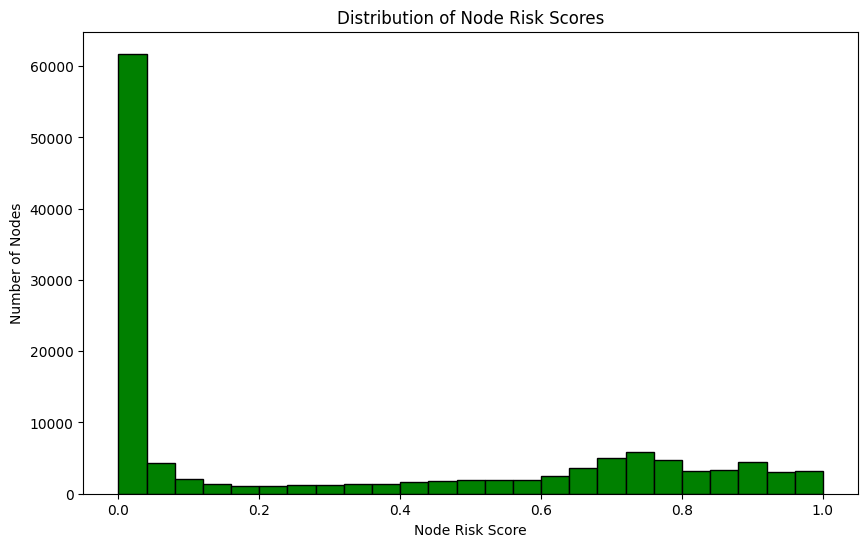

In [152]:
plt.figure(figsize=(10,6))

plt.hist(
    risk_df['Risk_Score'],
    bins=25,
    edgecolor='black',
    color='green'
)

plt.xlabel('Node Risk Score')
plt.ylabel('Number of Nodes')
plt.title('Distribution of Node Risk Scores')

plt.show()

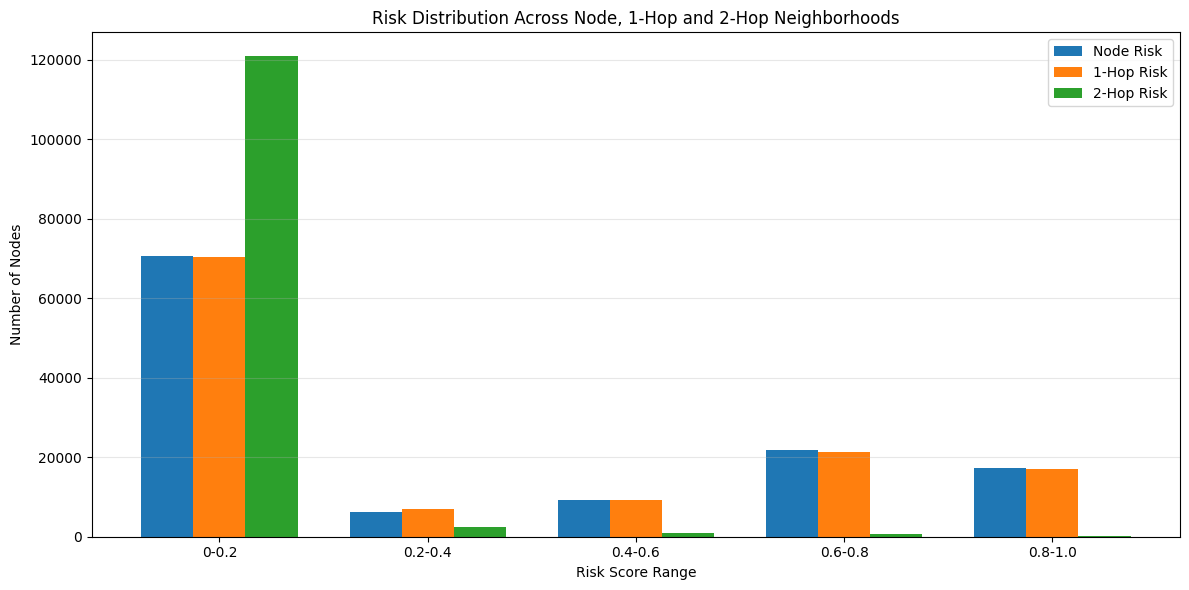

In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

bins = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

labels = [
    '0-0.2',
    '0.2-0.4',
    '0.4-0.6',
    '0.6-0.8',
    '0.8-1.0'
]

# Count nodes in each bucket

node_counts = pd.cut(
    risk_df['Risk_Score'],
    bins=bins,
    labels=labels,
    include_lowest=True
).value_counts().sort_index()

neighbor_counts = pd.cut(
    risk_df['Neighbor_Risk'],
    bins=bins,
    labels=labels,
    include_lowest=True
).value_counts().sort_index()

twohop_counts = pd.cut(
    risk_df['2-hop Neighbor_Risk'],
    bins=bins,
    labels=labels,
    include_lowest=True
).value_counts().sort_index()

# Plot

x = np.arange(len(labels))
width = 0.25

plt.figure(figsize=(12,6))

plt.bar(
    x - width,
    node_counts,
    width,
    label='Node Risk'
)

plt.bar(
    x,
    neighbor_counts,
    width,
    label='1-Hop Risk'
)

plt.bar(
    x + width,
    twohop_counts,
    width,
    label='2-Hop Risk'
)

plt.xticks(x, labels)

plt.xlabel('Risk Score Range')
plt.ylabel('Number of Nodes')
plt.title('Risk Distribution Across Node, 1-Hop and 2-Hop Neighborhoods')

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

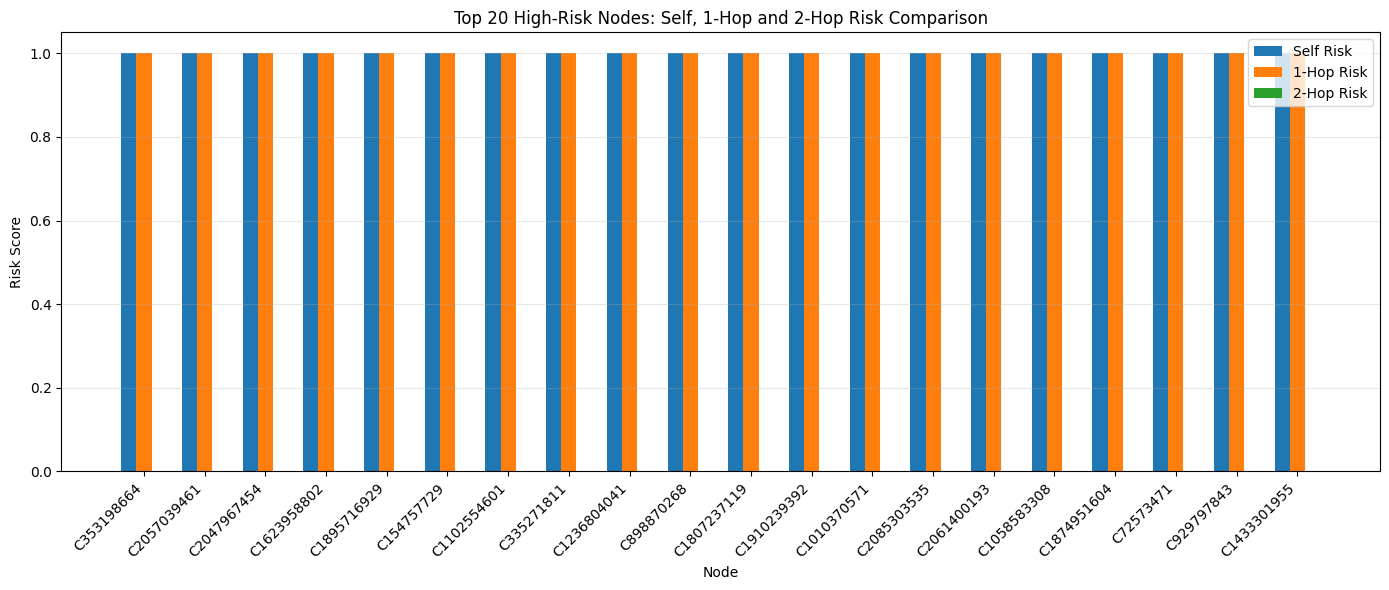

In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Top 20 highest-risk nodes
top20 = risk_df.sort_values(
    by='Risk_Score',
    ascending=False
).head(20)

x = np.arange(len(top20))
width = 0.25

plt.figure(figsize=(14,6))

plt.bar(
    x - width,
    top20['Risk_Score'],
    width,
    label='Self Risk'
)

plt.bar(
    x,
    top20['Neighbor_Risk'],
    width,
    label='1-Hop Risk'
)

plt.bar(
    x + width,
    top20['2-hop Neighbor_Risk'],
    width,
    label='2-Hop Risk'
)

plt.xticks(
    x,
    top20['Node_Name'],
    rotation=45,
    ha='right'
)

plt.xlabel('Node')
plt.ylabel('Risk Score')
plt.title('Top 20 High-Risk Nodes: Self, 1-Hop and 2-Hop Risk Comparison')

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

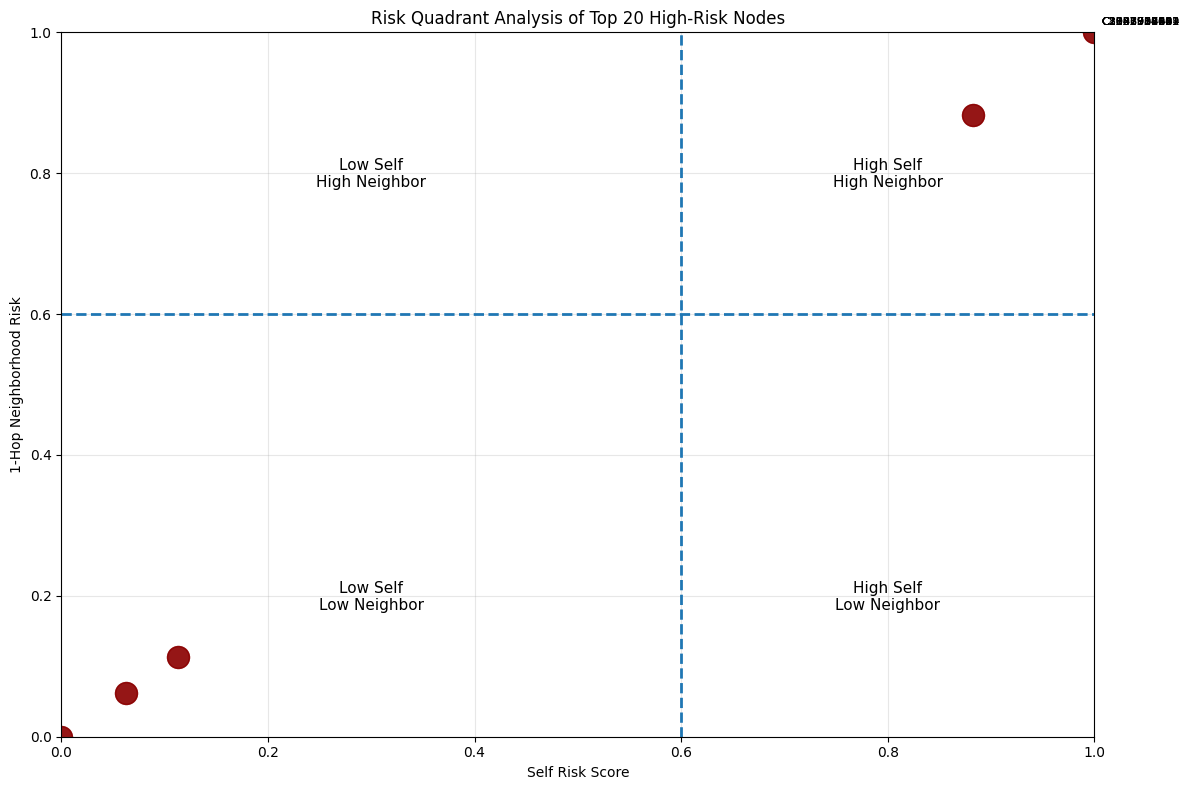

In [155]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Top 10 highest self-risk nodes
top10 = risk_df.sort_values(
    by='Risk_Score',
    ascending=False
).head(10)



scaler = MinMaxScaler()

top10[['Risk_Score_Norm','Risk_Score_Norm']] = scaler.fit_transform(
    top10[['Risk_Score','Neighbor_Risk']]
)

# Axes
x = top10['Risk_Score_Norm']
y = top10['Risk_Score_Norm']

# Thresholds
x_mid = 0.6
y_mid = 0.6

plt.figure(figsize=(12,8))

plt.scatter(
    x,
    y,
    s=250,
    alpha=0.7,
    color='darkred'
)

# Add node labels
for _, row in top10.iterrows():

    plt.annotate(
        row['Node_Name'],
        (row['Risk_Score'],
         row['Neighbor_Risk']),
        fontsize=8,
        xytext=(5,5),
        textcoords='offset points'
    )

# Quadrant lines
plt.axvline(
    x=x_mid,
    linestyle='--',
    linewidth=2
)

plt.axhline(
    y=y_mid,
    linestyle='--',
    linewidth=2
)

# Quadrant titles
plt.text(
    x_mid*0.5,
    y_mid*1.3,
    'Low Self\nHigh Neighbor',
    fontsize=11,
    ha='center'
)

plt.text(
    (x_mid+1)/2,
    y_mid*1.3,
    'High Self\nHigh Neighbor',
    fontsize=11,
    ha='center'
)

plt.text(
    x_mid*0.5,
    y_mid*0.3,
    'Low Self\nLow Neighbor',
    fontsize=11,
    ha='center'
)

plt.text(
    (x_mid+1)/2,
    y_mid*0.3,
    'High Self\nLow Neighbor',
    fontsize=11,
    ha='center'
)

plt.xlabel('Self Risk Score')
plt.ylabel('1-Hop Neighborhood Risk')
plt.title('Risk Quadrant Analysis of Top 20 High-Risk Nodes')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Now the application will do a practive validation on the transaction. It will ask input, source and destination account from the user and calculate the risk score and pop up an warning message before transaction intiatiated**

In [156]:
risk_df.head()

,Node_ID,Node_Name,Risk_Score,Node_Txn_Count,Neighbor_Risk,2-hop Neighbor_Risk
0,62634,C353198664,0.999993,1,0.999993,0.0
1,125218,C2057039461,0.999993,1,0.999993,0.0
2,124001,C2047967454,0.999990,1,0.999990,0.0
3,57696,C1623958802,0.999990,1,0.999990,0.0
4,130620,C1895716929,0.999970,1,0.999970,0.0


**Showing expected data format for input**

In [157]:
valid_customers = set(risk_df['Node_Name'].astype(str))

customer_lengths = risk_df['Node_Name'].astype(str).str.len()

MIN_LENGTH = customer_lengths.min()
MAX_LENGTH = customer_lengths.max()

print(f"Valid customer ID length: {MIN_LENGTH} to {MAX_LENGTH}")

Valid customer ID length: 6 to 11


In [158]:
# Example customer IDs:
# C1234567890

sample_id = risk_df['Node_Name'].iloc[0]

EXPECTED_PREFIX = sample_id[0]
EXPECTED_LENGTH = len(sample_id)

print(f"Expected format: {EXPECTED_PREFIX} followed by "
      f"{MIN_LENGTH} to {MAX_LENGTH} characters")

Expected format: C followed by 6 to 11 characters


Printing the valid input rules

In [159]:
print(
    "\nAccount Validation Rules:"
    f"\n• Must start with '{EXPECTED_PREFIX}'"
    f"\n• Must contain between {MIN_LENGTH} to {MAX_LENGTH} characters"
    "\n• Must exist in the customer risk database"
)


Account Validation Rules:
• Must start with 'C'
• Must contain between 6 to 11 characters
• Must exist in the customer risk database


Input validation function

In [160]:
def validate_customer_id(customer_id,
                         valid_customers,
                         expected_prefix):

    customer_id = customer_id.strip()

    # Prefix check
    if not customer_id.startswith(expected_prefix):
        print(
            f"\n❌ Invalid prefix."
            f"\nCustomer IDs must start with '{expected_prefix}'."
        )
        return False

    # Exists in dataset check
    if customer_id not in valid_customers:
        print(
            "\n❌ Customer ID not found in risk dataset."
            "\nPlease enter a valid account."
        )
        return False

    return True

Getting the ***source account and validate***

In [161]:


while True:

    source_id = input(
        f"\nEnter Source Account "
        f"(Starts with '{EXPECTED_PREFIX}', "
    ).strip()

    if validate_customer_id(
        source_id,
        valid_customers,
        EXPECTED_PREFIX
    ):
        break

getting the ***target account and validate***

In [162]:
while True:

    destination_id = input(
        f"\nEnter Destination Account "
        f"(Starts with '{EXPECTED_PREFIX}', "
    ).strip()

    if destination_id == source_id:
        print(
            "\n❌ Source and Destination "
            "cannot be the same."
        )
        continue

    if validate_customer_id(
        destination_id,
        valid_customers,
        EXPECTED_PREFIX
    ):
        break

getting the details of **source and target account** profiles

In [163]:
source_profile = (
    risk_df[risk_df['Node_Name'] == source_id]
    .iloc[0]
)

destination_profile = (
    risk_df[risk_df['Node_Name'] == destination_id]
    .iloc[0]
)

**calculating risk score**

In [164]:
source_score = (
    source_profile['Risk_Score']
    + source_profile['Neighbor_Risk']
    + source_profile['2-hop Neighbor_Risk']
) / 3

destination_score = (
    destination_profile['Risk_Score']
    + destination_profile['Neighbor_Risk']
    + destination_profile['2-hop Neighbor_Risk']
) / 3

transaction_risk = (
    source_score + destination_score
) / 2

In [165]:
if transaction_risk >= 0.7:
    recommendation = "BLOCK"

elif transaction_risk >= 0.4:
    recommendation = "REVIEW"

else:
    recommendation = "ALLOW"

**Display the Risk Result**

In [166]:
print("\n" + "="*50)
print("PRE-TRANSACTION RISK ASSESSMENT")
print("="*50)

print(f"\nSource Account      : {source_id}")
print(f"Destination Account : {destination_id}")

print("\nSource Risk Profile")
print(f"Risk Score    : {source_profile['Risk_Score']:.3f}")
print(f"1-Hop Risk    : {source_profile['Neighbor_Risk']:.3f}")
print(f"2-Hop Risk    : {source_profile['2-hop Neighbor_Risk']:.3f}")

print("\nDestination Risk Profile")
print(f"Risk Score    : {destination_profile['Risk_Score']:.3f}")
print(f"1-Hop Risk    : {destination_profile['Neighbor_Risk']:.3f}")
print(f"2-Hop Risk    : {destination_profile['2-hop Neighbor_Risk']:.3f}")

print(f"\nTransaction Risk : {transaction_risk:.3f}")
print(f"Recommendation  : {recommendation}")

print("="*50)


PRE-TRANSACTION RISK ASSESSMENT

Source Account      : C1010370571
Destination Account : C1058583308

Source Risk Profile
Risk Score    : 1.000
1-Hop Risk    : 1.000
2-Hop Risk    : 0.000

Destination Risk Profile
Risk Score    : 1.000
1-Hop Risk    : 1.000
2-Hop Risk    : 0.000

Transaction Risk : 0.667
Recommendation  : REVIEW
